# 03b - Unsupervised Learning

## Purpose

This notebook will be utilized for unsupervised exploratory analysis and clustering of U.S. counties using healthcare-resource, SVI, and HPSA features. 

## Goals

Our primary questions are: 
- What healthcare-access and social-vulnerability cluster profiles emerge among U.S. counties?
- What can these clusters teach us that we wouldn't have learned from looking at individual variables alone?

## Data Sources

From notebook 02, we will be loading master_county_analytical.csv and feature_manifest.csv. The routine-checkup outcome is excluded from clustering and will only be used for descriptive comparison afterward.

## 1. Imports and Paths

In [58]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn import metrics
from sklearn.metrics import adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

import json
from urllib.request import urlopen
import plotly.express as px

PROJECT_ROOT = Path("..")
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
REFERENCE_DIR = DATA_DIR / "reference"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
FIG_DIR = PROJECT_ROOT / "figures" / "unsupervised"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR = RESULTS_DIR / "unsupervised"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42  

### Helper Functions for Saving Figures and Tables

In [59]:
# helper functions to save all figures and tables in unsupervised subfolders of "figures"

def save_fig(filename):
    plt.savefig(FIG_DIR / filename, dpi=300, bbox_inches="tight")

def save_table(df, filename, decimals=2):
    """Round a table, save it as CSV to results/unsupervised/, and display it.
    Keeps the index only if it carries meaning (e.g., k or cluster names), not plain 0, 1, 2..."""
    out = df.round(decimals)
    keep_index = not isinstance(out.index, pd.RangeIndex)
    out.to_csv(TABLE_DIR / filename, index=keep_index)
    return out

## 2. Load In Cleaned and Merged Data

In [60]:
shared_analytical = pd.read_csv(
    PROCESSED_DIR / "master_county_analytical.csv",
    dtype={"fips": "string"},
    low_memory=False
)

feature_manifest = pd.read_csv(REFERENCE_DIR / "feature_manifest.csv")

print(shared_analytical.shape)
feature_manifest["analysis"].value_counts()

(3144, 50)


analysis
unsupervised                           27
supervised_svi_sensitivity             16
reference                              12
supervised                             11
unsupervised_sensitivity                6
supervised_sensitivity                  5
unsupervised_hpsa_score_sensitivity     3
Name: count, dtype: int64

In [61]:
identifier_cols = ["fips", "state_abbr", "county_name_places", "places_target_year"]
target_col = "routine_checkup_pct"

def variables_for(group):
    return feature_manifest.loc[feature_manifest["analysis"] == group, "variable"].tolist()

unsupervised_primary_candidates = variables_for("unsupervised")
unsupervised_sensitivity_candidates = variables_for("unsupervised_sensitivity")
unsupervised_hpsa_score_sensitivity = variables_for("unsupervised_hpsa_score_sensitivity")

print("Primary:", unsupervised_primary_candidates)
print("Sensitivity:", unsupervised_sensitivity_candidates)
print("HPSA score sensitivity:", unsupervised_hpsa_score_sensitivity)

Primary: ['primary_care_physicians_per_100k', 'nurse_practitioners_per_100k', 'physician_assistants_per_100k', 'hospitals_per_100k', 'hospital_beds_per_1000', 'fqhcs_per_100k', 'rural_health_clinics_per_100k', 'log_population_density', 'pc_hpsa_any', 'mh_hpsa_any', 'dh_hpsa_any', 'EP_POV150', 'EP_UNEMP', 'EP_HBURD', 'EP_NOHSDP', 'EP_UNINSUR', 'EP_AGE65', 'EP_AGE17', 'EP_DISABL', 'EP_SNGPNT', 'EP_LIMENG', 'EP_MINRTY', 'EP_MUNIT', 'EP_MOBILE', 'EP_CROWD', 'EP_NOVEH', 'EP_GROUPQ']
Sensitivity: ['pc_hpsa_count', 'mh_hpsa_count', 'dh_hpsa_count', 'popn_densty_per_squr_mi_20', 'rural_urban_contnm_23', 'pers_noins_lt65_pct_21']
HPSA score sensitivity: ['pc_hpsa_max_score', 'mh_hpsa_max_score', 'dh_hpsa_max_score']


In [62]:
# primary candidates split into 3 domains
unsupervised_svi_features = [c for c in unsupervised_primary_candidates if c.startswith("EP_")]
unsupervised_hpsa_features = [c for c in unsupervised_primary_candidates if c.endswith("_hpsa_any")]
unsupervised_resource_features = [c for c in unsupervised_primary_candidates if c not in unsupervised_svi_features + unsupervised_hpsa_features]

print(len(unsupervised_svi_features), len(unsupervised_hpsa_features), len(unsupervised_resource_features))

16 3 8


In [63]:
# what to cluster on and identifiers for labeling
unsupervised_primary_view = shared_analytical[identifier_cols + unsupervised_primary_candidates].copy()

# setting aside for post-clustering analysis
cluster_outcome_reference = shared_analytical[identifier_cols + [target_col]].copy()

unsupervised_primary_view.head()

,fips,state_abbr,county_name_places,places_target_year,primary_care_physicians_per_100k,nurse_practitioners_per_100k,physician_assistants_per_100k,hospitals_per_100k,hospital_beds_per_1000,fqhcs_per_100k,...,EP_AGE17,EP_DISABL,EP_SNGPNT,EP_LIMENG,EP_MINRTY,EP_MUNIT,EP_MOBILE,EP_CROWD,EP_NOVEH,EP_GROUPQ
0,06045,CA,Mendocino,2022,80.193355,83.534745,32.300101,3.341390,1.314280,15.593152,...,21.1,18.7,7.0,4.4,37.2,4.4,9.9,4.9,8.0,2.7
1,02063,AK,Chugach,2022,145.475706,14.547571,29.095141,0.000000,0.000000,NaN,...,21.7,15.9,5.4,1.7,29.5,10.1,15.6,5.6,5.7,3.6
2,04007,AZ,Gila,2022,50.072327,53.781388,38.945143,3.709061,1.131264,3.709061,...,19.4,21.2,3.6,0.6,38.8,1.2,19.8,4.4,6.9,2.3
3,05087,AR,Madison,2022,22.875443,51.469747,0.000000,0.000000,0.000000,5.718861,...,23.4,19.8,6.3,0.0,24.2,1.1,18.2,3.5,3.2,0.5
4,05067,AR,Jackson,2022,30.076997,102.261790,12.030799,6.015399,2.045236,12.030799,...,19.5,23.2,7.7,0.1,24.1,0.9,9.6,0.4,8.0,13.7


## 3. Exploratory Data Analysis

### 3.1 Evaluate and Correct for Skew in Features

In [64]:
# rename for ease of use with unsupervised EDA
features = unsupervised_primary_candidates
eda = shared_analytical[features].copy()

# sort features from greatest to least skew
summary = eda.describe(percentiles=[0.01, 0.05, 0.25, 0.50,0.75, 0.95, 0.99]).T
summary["skew"] = eda.skew()
summary.sort_values("skew", ascending=False)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew
physician_assistants_per_100k,3135.0,34.790598,44.580069,0.0,0.000000,0.000000,9.140350,24.918449,47.329632,103.185400,177.917888,1365.319772,10.261804
hospital_beds_per_1000,3135.0,2.821782,5.008714,0.0,0.000000,0.000000,0.537591,1.702651,3.329262,8.969230,20.756035,134.328358,10.018877
EP_NOVEH,3144.0,6.023123,4.425166,0.0,0.900000,2.100000,4.000000,5.300000,7.200000,11.000000,17.171000,85.900000,7.655245
EP_CROWD,3144.0,2.358842,2.343162,0.0,0.000000,0.400000,1.200000,1.800000,2.800000,5.900000,10.614000,40.700000,5.933926
fqhcs_per_100k,3131.0,7.455644,14.364377,0.0,0.000000,0.000000,0.000000,2.734845,8.345855,31.205731,73.240803,207.612457,5.056345
EP_LIMENG,3144.0,1.589440,2.635562,0.0,0.000000,0.000000,0.300000,0.700000,1.700000,6.385000,13.300000,36.400000,4.361318
hospitals_per_100k,3135.0,5.605345,9.426890,0.0,0.000000,0.000000,0.838840,2.653576,6.154794,21.623168,48.449612,103.466115,4.113206
EP_GROUPQ,3144.0,3.469084,4.336965,0.0,0.000000,0.500000,1.200000,2.000000,3.900000,11.485000,23.800000,43.000000,3.713035
EP_MUNIT,3144.0,4.896978,5.948255,0.0,0.000000,0.200000,1.400000,3.000000,6.100000,16.100000,27.614000,89.700000,3.664468
rural_health_clinics_per_100k,3131.0,10.359612,16.426827,0.0,0.000000,0.000000,0.000000,3.444475,14.452608,43.226423,75.197639,173.611111,3.009041


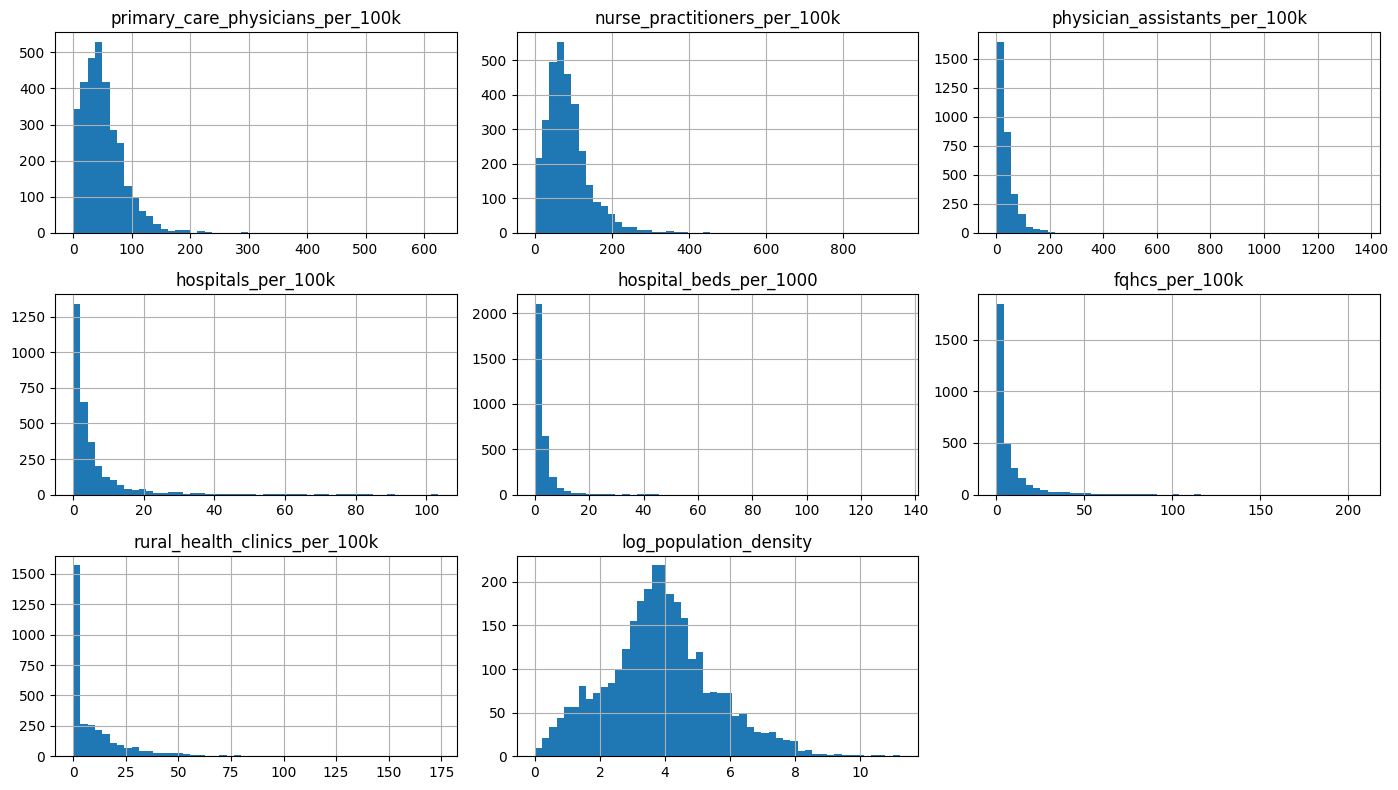

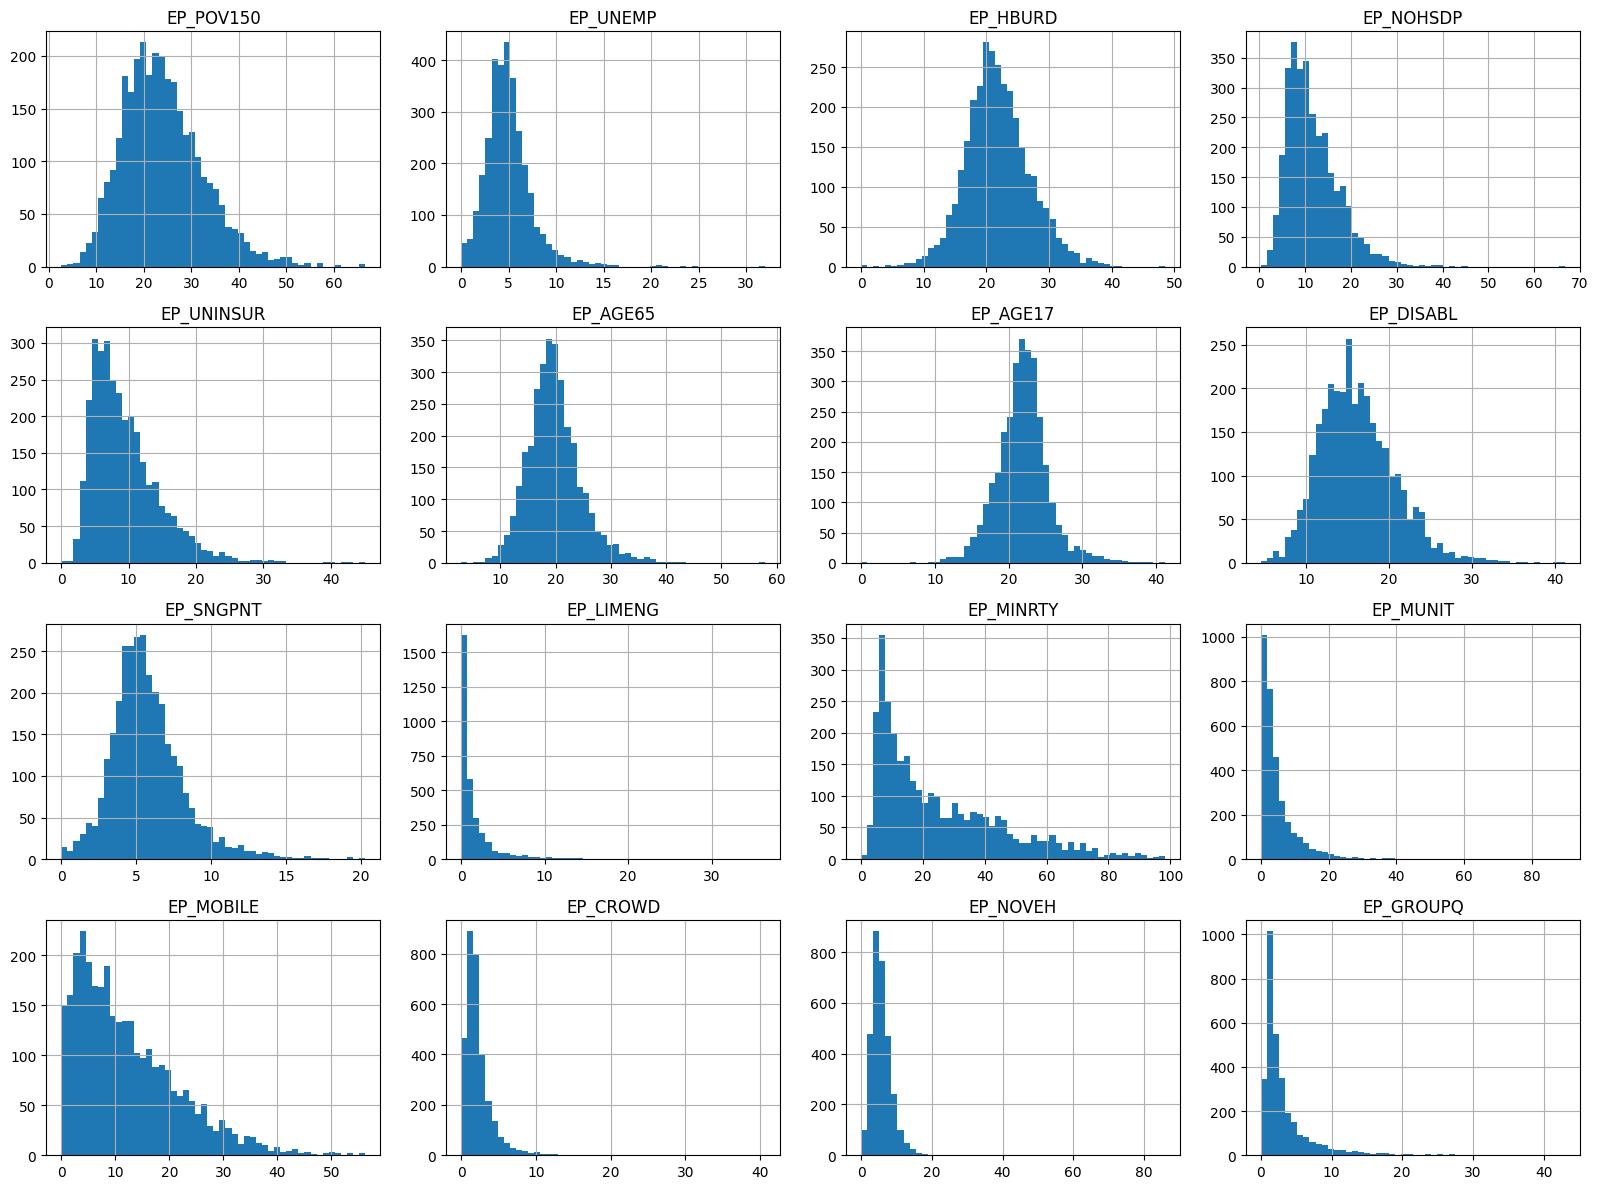

In [65]:
# visualize skew for all non-binary features (i.e. features not in unsupervised_hpsa_features)

eda[unsupervised_resource_features].hist(figsize=(14, 8), bins=50)
plt.tight_layout()
save_fig("hist_resource_features.png")

eda[unsupervised_svi_features].hist(figsize=(16, 12), bins=50)
plt.tight_layout()
save_fig("hist_svi_features.png")

In [66]:
# try transforming skewed features using log1p

skewed_features = [c for c in features
          if c not in unsupervised_hpsa_features
          and c != "log_population_density"
          and abs(eda[c].skew()) > 2]

pd.DataFrame({
    "skew_raw": eda[skewed_features].skew(),
    "skew_log1p": np.log1p(eda[skewed_features]).skew()
}).round(2)

,skew_raw,skew_log1p
primary_care_physicians_per_100k,2.56,-1.86
nurse_practitioners_per_100k,2.87,-2.38
physician_assistants_per_100k,10.26,-0.86
hospitals_per_100k,4.11,0.43
hospital_beds_per_1000,10.02,0.56
fqhcs_per_100k,5.06,0.45
rural_health_clinics_per_100k,3.01,0.27
EP_LIMENG,4.36,1.25
EP_MUNIT,3.66,0.33
EP_CROWD,5.93,0.64


The log transform worked well for most skewed features but overcorrected for two: primary_care_physicians_per_100k and nurse_practitioners_per_100k. This may reflect too many counties having zero primary care physicians and zero nurse practitioners. We want to retain these zeros because they reflect a notable lack of care access, so a square root transform may work better to address their skew.  

In [67]:
# number of counties with zero for these features
(eda[["primary_care_physicians_per_100k", "nurse_practitioners_per_100k"]] == 0).sum()

primary_care_physicians_per_100k    246
nurse_practitioners_per_100k        112
dtype: int64

In [68]:
pd.DataFrame({
    "skew_raw": eda[["primary_care_physicians_per_100k", "nurse_practitioners_per_100k"]].skew(),
    "skew_sqrt": np.sqrt(eda[["primary_care_physicians_per_100k", "nurse_practitioners_per_100k"]]).skew()
}).round(2)

,skew_raw,skew_sqrt
primary_care_physicians_per_100k,2.56,-0.24
nurse_practitioners_per_100k,2.87,0.10


To summarize, for PCP and NP rates, we will use a square root transform because log1p overcorrected. For 10 other skewed features, we will use log1p where skew > 2 (the threshold established in notebook 02). This transformation reduced the skew of these features to below about 1.3. Remaining features will not be transformed as they are not highly skewed (and log_population_density is already logged). 

The following function can be used to keep feature transformations consistent at later steps.

In [69]:
sqrt_features = ["primary_care_physicians_per_100k", "nurse_practitioners_per_100k"]
log_features = [feat for feat in skewed_features if feat not in sqrt_features]

def apply_transforms(df):
    transformed = df.copy()
    transformed[log_features] = np.log1p(transformed[log_features])
    transformed[sqrt_features] = np.sqrt(transformed[sqrt_features])
    return transformed

apply_transforms(eda).head()

,primary_care_physicians_per_100k,nurse_practitioners_per_100k,physician_assistants_per_100k,hospitals_per_100k,hospital_beds_per_1000,fqhcs_per_100k,rural_health_clinics_per_100k,log_population_density,pc_hpsa_any,mh_hpsa_any,...,EP_AGE17,EP_DISABL,EP_SNGPNT,EP_LIMENG,EP_MINRTY,EP_MUNIT,EP_MOBILE,EP_CROWD,EP_NOVEH,EP_GROUPQ
0,8.955074,9.139734,3.505560,1.468195,0.839099,2.808990,2.174363,3.299534,1,1,...,21.1,18.7,7.0,1.686399,37.2,1.686399,9.9,1.774952,2.197225,1.308333
1,12.061331,3.814128,3.404364,0.000000,0.000000,NaN,NaN,0.587787,1,0,...,21.7,15.9,5.4,0.993252,29.5,2.406945,15.6,1.887070,1.902108,1.526056
2,7.076180,7.333579,3.687507,1.549489,0.756715,1.549489,2.495450,2.501436,1,1,...,19.4,21.2,3.6,0.470004,38.8,0.788457,19.8,1.686399,2.066863,1.193922
3,4.782828,7.174242,0.000000,0.000000,0.000000,1.904919,0.000000,3.034953,1,1,...,23.4,19.8,6.3,0.000000,24.2,0.741937,18.2,1.504077,1.435085,0.405465
4,5.484250,10.112457,2.567316,1.948108,1.113578,2.567316,0.000000,3.310543,0,1,...,19.5,23.2,7.7,0.095310,24.1,0.641854,9.6,0.336472,2.197225,2.687847


### 3.2 Evaluate and Correct for Missingness

In [70]:
eda.isna().sum()

primary_care_physicians_per_100k     9
nurse_practitioners_per_100k         9
physician_assistants_per_100k        9
hospitals_per_100k                   9
hospital_beds_per_1000               9
fqhcs_per_100k                      13
rural_health_clinics_per_100k       13
log_population_density               9
pc_hpsa_any                          0
mh_hpsa_any                          0
dh_hpsa_any                          0
EP_POV150                            0
EP_UNEMP                             0
EP_HBURD                             0
EP_NOHSDP                            0
EP_UNINSUR                           0
EP_AGE65                             0
EP_AGE17                             0
EP_DISABL                            0
EP_SNGPNT                            0
EP_LIMENG                            0
EP_MINRTY                            0
EP_MUNIT                             0
EP_MOBILE                            0
EP_CROWD                             0
EP_NOVEH                 

In [71]:
# which counties are missing and where
missing_rows = shared_analytical.loc[
    eda.isna().any(axis=1),
    ["fips", "state_abbr", "county_name_places"]
]

missing_rows[["fips", "state_abbr", "county_name_places"]]

,fips,state_abbr,county_name_places
1,02063,AK,Chugach
60,02195,AK,Petersburg
78,02066,AK,Copper River
222,02275,AK,Wrangell
273,09130,CT,Lower Connecticut River Valley
282,09110,CT,Capitol
354,09150,CT,Northeastern Connecticut
401,09180,CT,Southeastern Connecticut
439,09140,CT,Naugatuck Valley
450,09120,CT,Greater Bridgeport


In [72]:
# we know the issue with CT; what are the AK counties missing?

ak_missing = missing_rows[missing_rows["state_abbr"] == "AK"]
eda.loc[ak_missing.index]

,primary_care_physicians_per_100k,nurse_practitioners_per_100k,physician_assistants_per_100k,hospitals_per_100k,hospital_beds_per_1000,fqhcs_per_100k,rural_health_clinics_per_100k,log_population_density,pc_hpsa_any,mh_hpsa_any,...,EP_AGE17,EP_DISABL,EP_SNGPNT,EP_LIMENG,EP_MINRTY,EP_MUNIT,EP_MOBILE,EP_CROWD,EP_NOVEH,EP_GROUPQ
1,145.475706,14.547571,29.095141,0.000000,0.000000,NaN,NaN,0.587787,1,0,...,21.7,15.9,5.4,1.7,29.5,10.1,15.6,5.6,5.7,3.6
60,178.571429,119.047619,0.000000,29.761905,8.035714,NaN,NaN,0.788457,1,1,...,18.0,19.0,3.5,6.8,45.4,3.6,8.6,1.6,12.6,3.9
78,0.000000,154.499807,115.874855,0.000000,0.000000,NaN,NaN,0.095310,1,1,...,26.5,19.0,6.1,0.0,47.6,1.1,8.2,2.4,7.0,0.9
222,144.927536,0.000000,0.000000,48.309179,10.628019,NaN,NaN,0.587787,1,1,...,22.1,23.1,4.4,0.1,44.4,1.7,8.2,1.4,6.3,2.6


In 2022, the Census Bureau replaced CT's 8 historical counties with 9 planning regions as the official county equivalents. The PLACES and SVI datasets use the new regions, however AHRF’s 2022 resource counts are still reported for the old 8 counties. Both counties and planning regions are built from towns, but the towns are grouped differently. In other words, one former county can be split across several regions, and one region can draw from several old counties. With 9 counties comprising only 0.3% of 3,144 counties, we will exclude them from clustering rather than using an imputation strategy. 

In contrast, the 4 AK counties are only missing values for the two features fqhcs_per_100k and rural_health_clinics_per_100k. We could drop these for ease or use a median imputation strategy to retain all the other data that is present for them. 

In [73]:
# drop CT (all 9 planning regions lack AHRF resource data)
cluster_base = shared_analytical.loc[
    shared_analytical["state_abbr"] != "CT",
    identifier_cols + features
].copy()

# fill the 4 missing AK with AK-only medians
ak = cluster_base["state_abbr"] == "AK"
impute_cols = ["fqhcs_per_100k", "rural_health_clinics_per_100k"]

for col in impute_cols:
    ak_median = cluster_base.loc[ak, col].median()
    cluster_base.loc[ak, col] = cluster_base.loc[ak, col].fillna(ak_median)

print(cluster_base.shape)
# use cluster_base DataFrame instead of eda DataFrame going forward

(3135, 31)


### 3.3 Evaluate Correlation and Correct for Redundancy

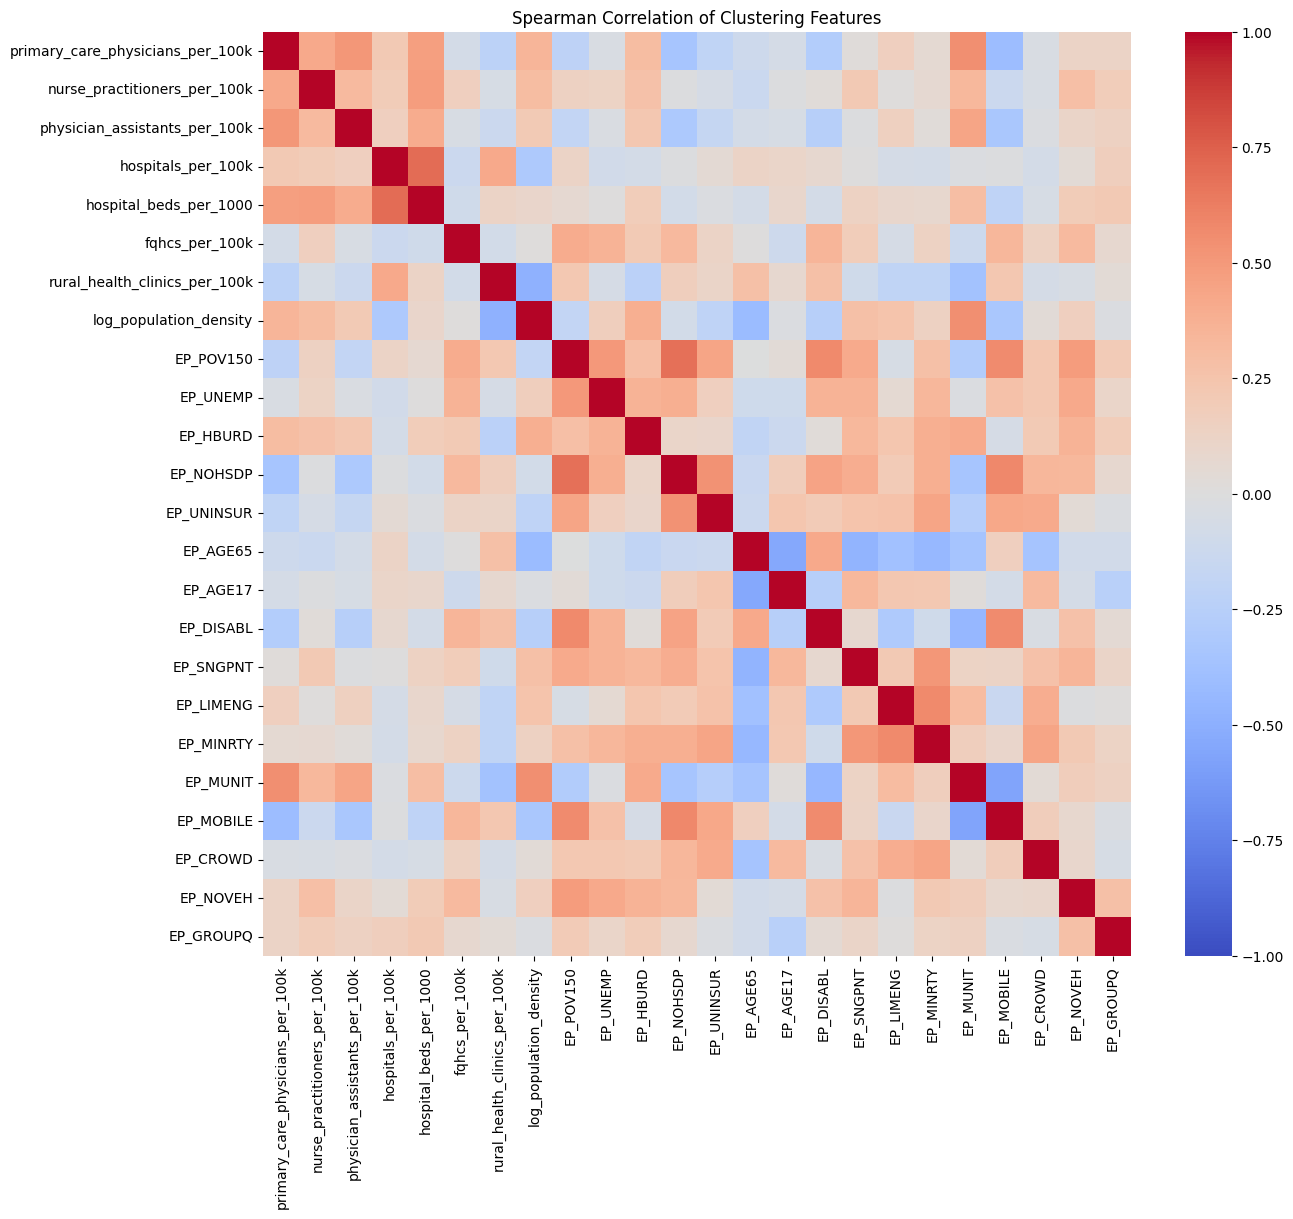

In [74]:
# look at correlation between continuous variables
continuous = unsupervised_resource_features + unsupervised_svi_features
corr = cluster_base[continuous].corr(method="spearman")

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman Correlation of Clustering Features")
save_fig("corr_heatmap_spearman.png")

In [75]:
strong_pairs = []
for i, var1 in enumerate(continuous):
    for var2 in continuous[i + 1:]:      
        spearman = corr.loc[var1, var2]
        if abs(spearman) >= 0.7:
            strong_pairs.append((var1, var2, round(spearman, 2)))

pd.DataFrame(strong_pairs, columns=["var1", "var2", "spearman"])

,var1,var2,spearman


An empty DataFrame for strong_pairs suggests pairwise redundancy is limited (no Spearman correlations are greater than .7) and therefore no features should be removed based on correlation grounds. Below we'll examine what the 10 highest values for the Spearman correlations are among all pairs.

In [76]:
all_pairs = []
for i, var1 in enumerate(continuous):
    for var2 in continuous[i + 1:]:
        all_pairs.append((var1, var2, round(corr.loc[var1, var2], 2)))

pd.DataFrame(all_pairs, columns=["var1", "var2", "spearman"]).sort_values(
    "spearman", key=abs, ascending=False
).head(10)

,var1,var2,spearman
66,hospitals_per_100k,hospital_beds_per_1000,0.70
158,EP_POV150,EP_NOHSDP,0.68
206,EP_NOHSDP,EP_MOBILE,0.59
162,EP_POV150,EP_DISABL,0.58
255,EP_LIMENG,EP_MINRTY,0.57
167,EP_POV150,EP_MOBILE,0.57
266,EP_MUNIT,EP_MOBILE,-0.57
244,EP_DISABL,EP_MOBILE,0.56
18,primary_care_physicians_per_100k,EP_MUNIT,0.55
151,log_population_density,EP_MUNIT,0.55


The strongest correlation is hospitals_per_100k and hospital_beds_per_1000 (rounded up to 0.70). While this pair is on the borderline of a "strong" correlation, each feature merits being retained because each captures distinct aspects of hospital access; the *presence* of facilities is distinct from the inpatient *capacity* of those facilities. 

The more moderate correlations between other features reflect different aspects of economic hardship that often move together (poverty (EP_POV150), no high school diploma (EP_NOHSDP), mobile homes (EP_MOBILE), and disability (EP_DISABL)) and urban/rural divides (population density correlating positively with number of PCPs and multi-unit housing (EP_MUNIT), and multi-unit housing (EP_MUNIT) correlating negatively with mobile homes (EP_MOBILE)). 

### 3.4 Evaluate HPSA Binary Features

In [77]:
cluster_base[unsupervised_hpsa_features].mean().round(2)

pc_hpsa_any    0.86
mh_hpsa_any    0.89
dh_hpsa_any    0.72
dtype: float64

HPSA presence indicators for Primary Care, Mental Health, and Dental Health are given as binary variables. With 72–89% of counties designated, these features may distinguish counties poorly and distort distance measures. As such, we will initially exclude them from the clustering matrix and use them afterward to describe clusters. A sensitivity analysis *including* these three features will assess whether this exclusion materially changes any cluster assignments, using the Adjusted Rand Index (ARI) to evaluate the two sets of cluster labels. 

### 3.5 Finding Domain Balance: Evaluate if SVI Dominates the Distance Structure

In [78]:
# run an initial K Means to determine if SVI features are dominating how clusters are formed 

# turn cols into a clustering matrix: apply transformations and scale
def prep(cols):
    X = apply_transforms(cluster_base)[cols]
    X = SimpleImputer(strategy="median").fit_transform(X)
    return StandardScaler().fit_transform(X)

# return the labels from an initial K Means clustering with 4 clusters
def km_labels(cols, k=4):
    return KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(prep(cols))

labels_all = km_labels(continuous) # use all 24 features
labels_svi = km_labels(unsupervised_svi_features) # use just the 16 SVI features
labels_res = km_labels(unsupervised_resource_features) # use just the 8 resource features

print("All vs. SVI-only:", round(adjusted_rand_score(labels_all, labels_svi), 2))
print("All vs. resource-only:", round(adjusted_rand_score(labels_all, labels_res), 2))

All vs. SVI-only: 0.29
All vs. resource-only: 0.42


In [79]:
# test if the choice of k was a contributor

labels_all = km_labels(continuous, k=3) # use all 24 features
labels_svi = km_labels(unsupervised_svi_features, k=3) # use just the 16 SVI features
labels_res = km_labels(unsupervised_resource_features, k=3) # use just the 8 resource features

print("All vs. SVI-only:", round(adjusted_rand_score(labels_all, labels_svi), 2))
print("All vs. resource-only:", round(adjusted_rand_score(labels_all, labels_res), 2))

All vs. SVI-only: 0.28
All vs. resource-only: 0.25


Because our clustering matrix contains 16 SVI features but only 8 resource features, we needed to determine whether SVI disproportionately drives the distance structure. We ran a quick K-means diagnostic for labels of *all* continuous features, SVI-only labels, and resource-only labels. Comparing solutions via ARI, neither domain alone reproduced the combined clustering, suggesting that the combined solution reflects both healthcare-resource and social-vulnerability structure rather than being driven by SVI’s larger feature count.

This diagnostic does not show that domain weighting is irrelevant. It only demonstrates that SVI does not overwhelm the equally weighted solution. We retained equal feature weighting for the primary analysis, which treats each indicator the same and preserves the full detail of the SVI domain. Later in the notebook, we test the effect of equal domain weighting directly as a sensitivity analysis (see 6.4).

### 3.6 Feature Decision Summary

**EDA Decisions**
- **Transformations:** For 10 skewed features, we will use log1p where skew > 2. This transformation reduced the skew of these features to below about 1.3. For PCP and NP rates, we will use a square root transform because log1p overcorrected. Remaining features will not be transformed as they are not highly skewed (and log_population_density is already logged).

- **Missing Data:** 13 counties had missing clustering features. Connecticut (9 planning regions) were excluded from clustering. AHRF 2022 resource data are reported for Connecticut’s former 8 counties, which do not map one-to-one onto the planning regions adopted as county equivalents in 2022. They remain in the shared dataset but will not be clustered. Alaska (4 census areas) only had missing values for FQHC and rural-health-clinic rates. These values were median-imputed (medians computed from other AK counties) since all other features are observed.

- **Correlation & Redundancy of Continuous Features:** Spearman correlations among the 24 continuous clustering features were examined. No pair reached a Spearman correlation coefficient greater than 0.7. The strongest correlation was hospitals per 100k and hospital beds per 1,000 (rho rounded to 0.70). These were both retained as features because they each capture distinct aspects of hospital access, i.e. the presence of facilities vs. the inpatiet capacity of those facilities. No features were removed on correlation or redundancy grounds.

- **HPSA Binary Features:** With 72–89% of counties designated, these features may distinguish counties poorly and distort distance measures. As such, we will initially exclude them from the clustering matrix and use them afterward to describe clusters. A sensitivity analysis *including* these three features will assess whether this exclusion significantly changes any cluster assignments.

- **Finding Domain Balance:** Diagnostic K-Means comparisons (ARI) showed that neither domain alone reproduced the combined clustering, so SVI’s larger feature count does not dominate the primary solution. Equal feature weighting is retained for the primary analysis. Because domain weighting may still affect cluster assignments, an equal-domain weighting sensitivity analysis is reported in 6.4.

- **Final candidate feature set:** 24 continuous features for 3,135 counties:
    - Healthcare resources (8): primary care physicians, nurse practitioners, and physician assistants per 100k; hospitals, FQHCs, and rural health clinics per 100k; hospital beds per 1,000; log population density
    - Social vulnerability (16): all SVI EP_ indicators
    - Excluded from primary clustering: HPSA presence flags (to be used for profiling and sensitivity analysis); routine-checkup prevalence (to be reserved for post-clustering comparison)

In [80]:
final_features = continuous

print(len(final_features)) 
cluster_base.shape[0]

24


3135

## 4. K-Means Clustering

### 4.1 Evaluate K-Means for k=2-10

In [81]:
X_final = prep(continuous) # apply transforms and scale

km_results = []

for k in range(2,11):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_final)
    
    row_dict = { 
        "k": k,                 # notes to self:
        "inertia": km.inertia_, # looking for the the "elbow", diminishing returns for increasing k
        "Silhouette Score": metrics.silhouette_score(X_final, km.labels_), # closer to 1 is better
        "Davies-Bouldin": metrics.davies_bouldin_score(X_final, km.labels_), # lower is better 
        "Calinski-Harabasz": metrics.calinski_harabasz_score(X_final, km.labels_) # higher is better
    }

    km_results.append(row_dict)

km_df = pd.DataFrame(km_results).set_index("k")

save_table(km_df, "kmeans_metrics_k2_10.csv", decimals=3)

,inertia,Silhouette Score,Davies-Bouldin,Calinski-Harabasz
k,,,,
2,65209.989,0.150,2.380,481.892
3,58219.254,0.118,2.131,457.829
4,54439.968,0.116,2.152,398.757
5,51507.046,0.123,2.076,360.553
6,49350.277,0.097,2.077,328.302
7,47633.245,0.085,2.093,302.149
8,46326.145,0.087,2.207,278.812
9,45187.307,0.084,2.228,259.876
10,44203.280,0.082,2.109,243.797


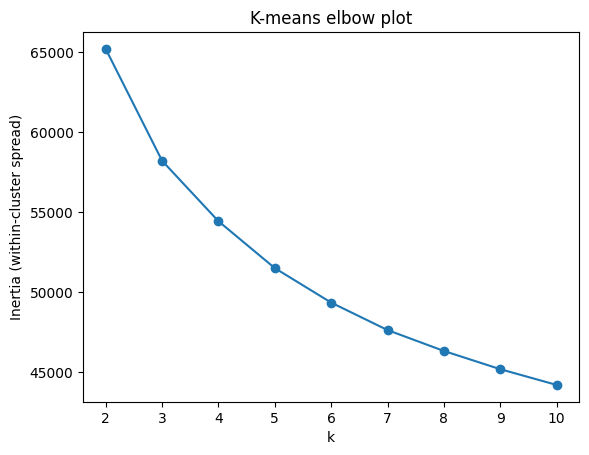

In [82]:
# visualize inertia
plt.plot(km_df.index, km_df["inertia"], marker="o")
plt.xlabel("k")
plt.ylabel("Inertia (within-cluster spread)")
plt.title("K-means elbow plot")
save_fig("kmeans_elbow.png")

We evaluated K-means solutions for k = 2–10. Silhouette and Calinski-Harabasz scores both favored k = 2. From an interpretability perspective, however, this is too imprecise of a clustering division to characterize distinct county profiles, and represents a broad division. Davies-Bouldin was minimized at k = 5, where silhouette also showed a local maximum and the inertia elbow curve flattened. Silhouette scores were notably low for *all* values of k (0.08–0.15), however, indicating substantial overlap among clusters. Consequently, the resulting clusters should be interpreted as profiles along a *continuum* rather than clearly delineated county types. We will do a quick stability check to confirm that k = 5 is a stable model choice before proceeding. 

### 4.2 Stability Check of K-Means at k = 2 and k = 5

In [83]:
for k in [2, 5]:
    base = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_final)
    scores = []
    for seed in [1, 7, 21, 99, 123]:
        other = KMeans(n_clusters=k, n_init=20, random_state=seed).fit_predict(X_final)
        scores.append(adjusted_rand_score(base, other))
    print(f"k={k}: mean ARI across seeds = {np.mean(scores):.3f}  (min {np.min(scores):.3f})")

k=2: mean ARI across seeds = 0.994  (min 0.992)
k=5: mean ARI across seeds = 0.992  (min 0.984)


Given the stability of the model at k = 5 (mean ARI 0.992, minimum ARI 0.984) and the reasoning above, we'll proceed with K-Means at k = 5.

### 4.3 Use PCA Scatter Plot to Visualize Overall Shape

In [84]:
# use PCA for visualization; project the 24-features onto 2 principal components 

pca_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_final)
X_2d = pca_2d.transform(X_final)

# figure out what the loadings of PC1 and PC2 are

loadings = pd.DataFrame(pca_2d.components_.T, index=continuous, columns=["PC1", "PC2"])
loadings.sort_values("PC1", key=abs, ascending=False).round(2)

,PC1,PC2
EP_POV150,0.37,-0.08
EP_NOHSDP,0.37,-0.07
EP_MINRTY,0.32,0.18
EP_SNGPNT,0.29,0.17
EP_UNINSUR,0.29,-0.04
EP_UNEMP,0.29,0.04
EP_MOBILE,0.26,-0.24
EP_CROWD,0.24,0.13
EP_NOVEH,0.22,0.15
fqhcs_per_100k,0.20,-0.05


If each feature contributed equally to loading with 24 features, it would have an absolute value of around 1 / sqrt 24 or about .20. Loadings above or below this value, therefore, give us a sense of which features are contributing more or less to the first two principal components.  

- **PC1: Social vulnerability measures dominate**
  
  Large positive values are poverty (0.37), no diploma (0.37), minority (0.32), single-parent households (0.29), uninsured (0.29), unemployment (0.29), and mobile homes (0.26), crowding (0.24), and no vehicle (0.22). Notably, resource features are near zero except for FQHCs per 100k at 0.20. In other words, higher PC1 means more socioeconomically vulnerable.
- **PC2: Highlights an urban/provider-rich vs. rural/rural clinic reliant and older divide**

  Large positive values are multi-unit housing (0.39), population density (0.34), PCPs (0.30), housing cost burden (0.26), PAs (0.26), and NPs (0.23). Large negative values are age 65+ (−0.27), mobile homes (−0.24), disability (−0.24), and rural health clinics (−0.23). In other words, higher PC2 means more urban with more providers while lower PC2 means rural, older, and more reliant on rural clinics. 


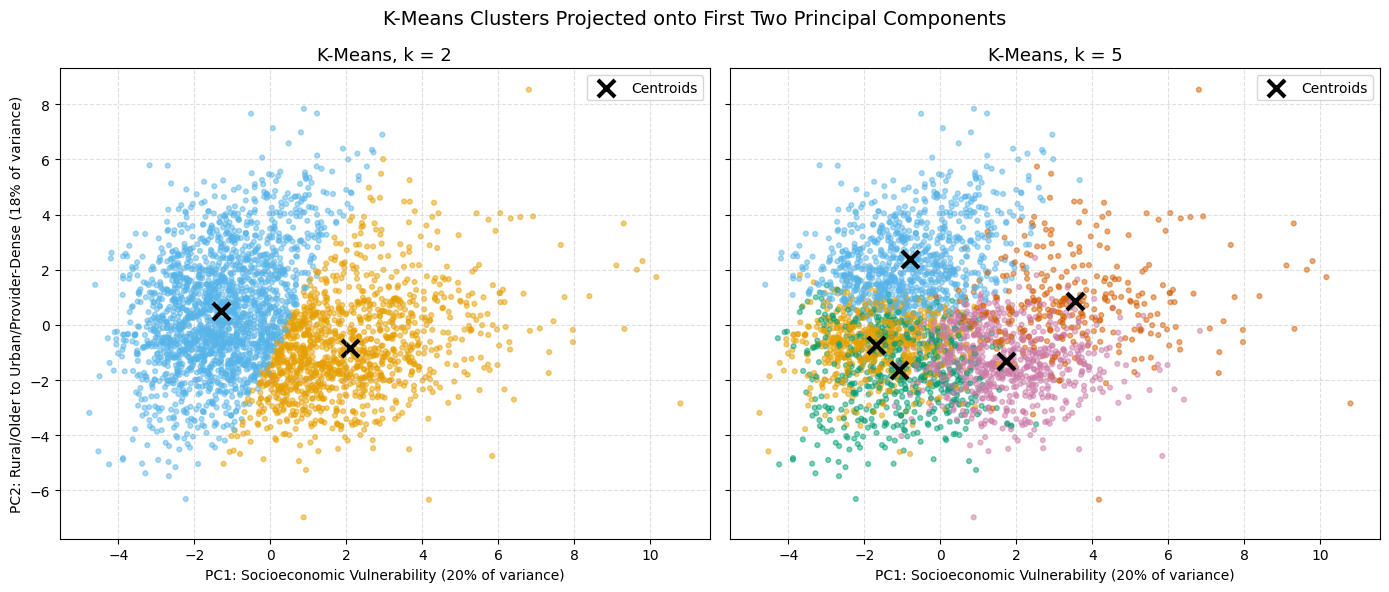

In [85]:
# Okabe-Ito colorblind-safe palette
cluster_palette = ["#E69F00", "#56B4E9", "#009E73", "#D55E00", "#CC79A7"]
palette = np.array(cluster_palette)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

for ax, k in zip(axes, [2, 5]):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_final)
    centroids_2d = pca_2d.transform(km.cluster_centers_)  

    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=palette[km.labels_], s=12, alpha=0.5)
    ax.scatter(centroids_2d[:, 0], centroids_2d[:, 1],
               c="black", marker="x", s=150, linewidths=3, label="Centroids")

    ax.set_title(f"K-Means, k = {k}", fontsize=13)
    ax.set_xlabel(f"PC1: Socioeconomic Vulnerability ({pca_2d.explained_variance_ratio_[0]:.0%} of variance)")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend()

axes[0].set_ylabel(f"PC2: Rural/Older to Urban/Provider-Dense ({pca_2d.explained_variance_ratio_[1]:.0%} of variance)")
plt.suptitle("K-Means Clusters Projected onto First Two Principal Components", fontsize=14)
plt.tight_layout()
save_fig("pca_scatter_kmeans.png")
plt.show()

The first two principal components explained 38% of total variance. Because the majority of variance lies outside this plane, however, the PCA projection is used for visualization only. *Interpreting* clusters relies on feature-level profiles.

### 4.4 Heat Map & Characterizing Cluster Profiles for K-Means at k=5

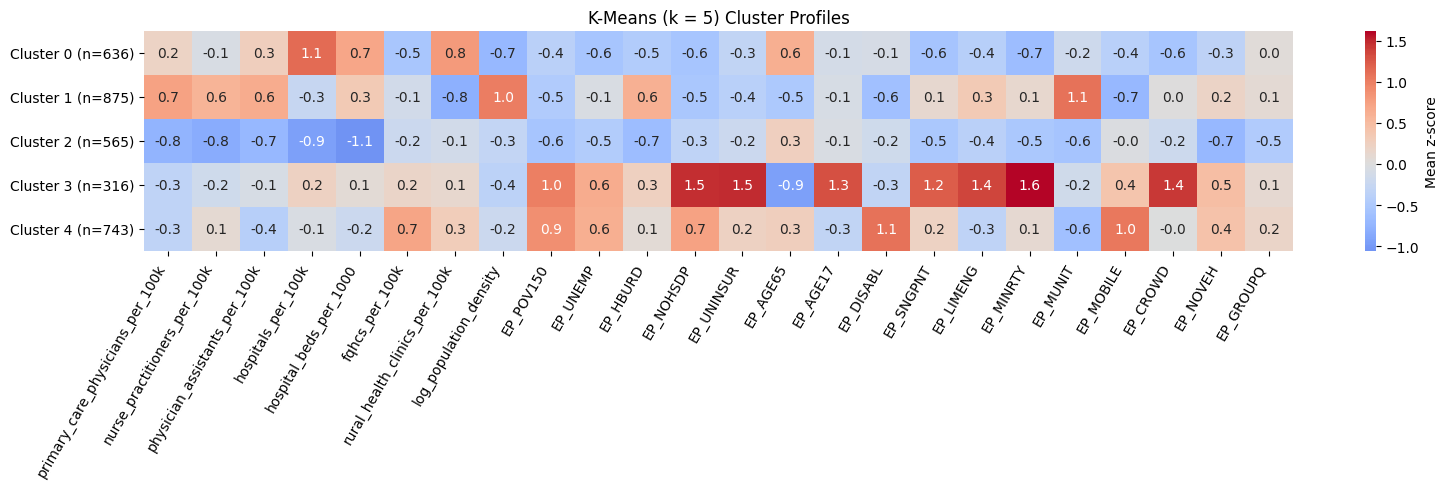

In [86]:
km5 = KMeans(n_clusters=5, n_init=20, random_state=RANDOM_STATE).fit(X_final)
cluster_base["kmeans_cluster"] = km5.labels_

# function for creating a heat map of mean standardized value of each feature in each cluster
def cluster_profile_heatmap(labels, title):
    profile = pd.DataFrame(X_final, columns=continuous).groupby(labels).mean()
    profile.index = [f"Cluster {c} (n={n})" for c, n in
                 zip(profile.index, pd.Series(labels).value_counts().sort_index())]

    plt.figure(figsize=(16, 5))
    sns.heatmap(profile, cmap="coolwarm", center=0, annot=True, fmt=".1f",
            cbar_kws={"label": "Mean z-score"})
    plt.title(title)
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()

cluster_profile_heatmap(km5.labels_, "K-Means (k = 5) Cluster Profiles")
save_fig("kmeans_cluster_profiles_heatmap.png")

**Characterizing the 5 Clusters**

We characterized cluster profiles using mean standardized feature values. We treated features with |z| ≥ 0.5 as notably above average, and those with |z| ≥ 1.0 as defining characteristics.

**Cluster 0: Rural, older, low-vulnerability, hospital-anchored access** (n = 636)
    
- Most defining characteristics: hospitals per 100k (1.1)
- Notably above average: rural health clinics per 100k (.8), hospital beds per 1000 (.7), age 65+ (.6)
- Notably below average: log population density (-0.7), minority (-0.7), unemployment (-0.6), no high school diploma (-0.6), single parent (-0.6), and crowding (-0.6), FQHCs (-0.5), housing burden (-0.5)

**Cluster 1: Provider-rich, low-vulnerability, urban/suburban** (n = 875)
    
- Most defining characteristics: population density (1.0), multi-unit housing (1.1)
- Notably above average: PCPs (0.7), NPs (0.6), PAs (0.6), housing cost burden (0.6)
- Notably below average: rural health clinics (−0.8), mobile homes (−0.7), disability (−0.6), poverty (−0.5), no high school diploma (−0.5), age 65+ (−0.5)

**Cluster 2: Healthcare resource-scarce, low-vulnerability** (n = 565)
    
- Most defining characteristics--notably below average on *every provider and facility measure*: PCPs (−0.8), NPs (−0.8), PAs (−0.7), hospitals (−0.9), beds (−1.1)
- Notably above average: n/a
- Also below average: poverty (−0.6), unemployment (−0.5), housing burden (−0.7), no vehicle (−0.7), multi-unit housing (−0.6), minority (−0.5), single parent (−0.5), group quarters (−0.5)

**Cluster 3: High-access barriers (uninsured/limited-English), young, avg healthcare resources** (n = 316)

- Most defining characteristics--notably all above average vulnerability measures: minority (1.6), no diploma (1.5), uninsured (1.5), limited English (1.4), crowding (1.4), age 17 and under (1.3), single parent (1.2), poverty (1.0)
- Also above average: unemployment (0.6), no vehicle (0.5)
- Notably below average: age 65+ (−0.9)
- Healthcare resources all roughly average

**Cluster 4: High-hardship (disability, poverty), FQHC-reliant** (n = 743)
    
- Most defining characteristics: disability (1.1), mobile homes (1.0)
- Notably above average: poverty (0.9), no diploma (0.7), FQHCs (0.7), unemployment (0.6)
- Notably below average: multi-unit housing (−0.6)


### 4.5 Choropleth Map to Visualize K-Means Cluster Profiles 

In [87]:
def save_map_html(fig, filename):
    """Save a Plotly map as a standalone interactive HTML file to keep the notebook small"""
    path = FIG_DIR / filename
    fig.write_html(path, include_plotlyjs="cdn")
    print(f"Saved interactive map to {path}")

In [88]:
with urlopen("https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json") as r:
    counties = json.load(r)

km_cluster_names = {
    0: "Rural, older, hospital-anchored",
    1: "Urban/suburban, provider-rich",
    2: "Resource-scarce, low-vulnerability",
    3: "High access barriers, young",
    4: "High-hardship, FQHC-reliant",
}

# function for choropleth map to visualize cluster profiles by FIPS

def choropleth_map(label_col, names, palette, title):
    
    """Choropleth of counties colored by cluster.
    label_col : column in cluster_base holding cluster labels
    names     : dict mapping cluster number to descriptive name
    palette   : list of colors, one per cluster (in cluster order)
    title     : plot title
    """
    map_df = cluster_base[["fips", "county_name_places", "state_abbr", label_col]].copy()
    map_df["cluster"] = map_df[label_col].map(names)

    fig = px.choropleth(
        map_df,
        geojson=counties,
        locations="fips",
        color="cluster",
        color_discrete_sequence=palette,
        category_orders={"cluster": [names[i] for i in sorted(names)]},
        scope="usa",
        hover_name="county_name_places",
        hover_data={"state_abbr": True, "fips": False},
        title=title,
    )
    fig.update_traces(marker_line_width=0)
    fig.update_layout(
    title_x=0.5,
    title_xanchor="center",   
    margin=dict(l=0, r=0, t=50, b=0),
    legend=dict(orientation="h", yanchor="top", y=-0.02, xanchor="center", x=0.5),
    legend_title_text=""
    )
    return fig

km_choropleth = choropleth_map("kmeans_cluster", km_cluster_names, cluster_palette,
                 "County Healthcare Access and Social Vulnerability Profiles (K-Means, k = 5)")

save_map_html(km_choropleth, "map_kmeans_k5.html")

# Interactive map saved to figures/unsupervised/map_kmeans_k5.html

Saved interactive map to ../figures/unsupervised/map_kmeans_k5.html


These clusters support the PCA finding that **vulnerability and healthcare access vary independently**. For instance, Cluster 2 is provider- and facility-scarce, yet has low social vulnerability. Likewise, Clusters 3 and 4 are both high-vulnerability, but in very different ways. Cluster 3 has a higher proportion of young, minority, uninsured, and limited-English speakers whereas Cluster 4 tends to have an older population with hardship around disability and poverty. 

Rather than looking at boxplots of all 24 features, below we'll look at 8 that seem to roughly separate the cluster profiles and look at their spread and overlap. 

- primary_care_physicians_per_100k (a provider supply measure)
- hospital_beds_per_1000 (hospital capacity, which separates Clusters 0 and 2)
- log_population_density (an urbanicity measure)
- EP_POV150 (a hardship measure)
- EP_UNINSUR (an access barrier measure helping define Cluster 3)
- EP_LIMENG (another access barrier measure helping define Cluster 3) 
- EP_DISABL (a defining hardship measure of Cluster 4)
- EP_AGE65 (a population age measure)

### 4.6 Boxplots of Key Features Separating Cluster Profiles

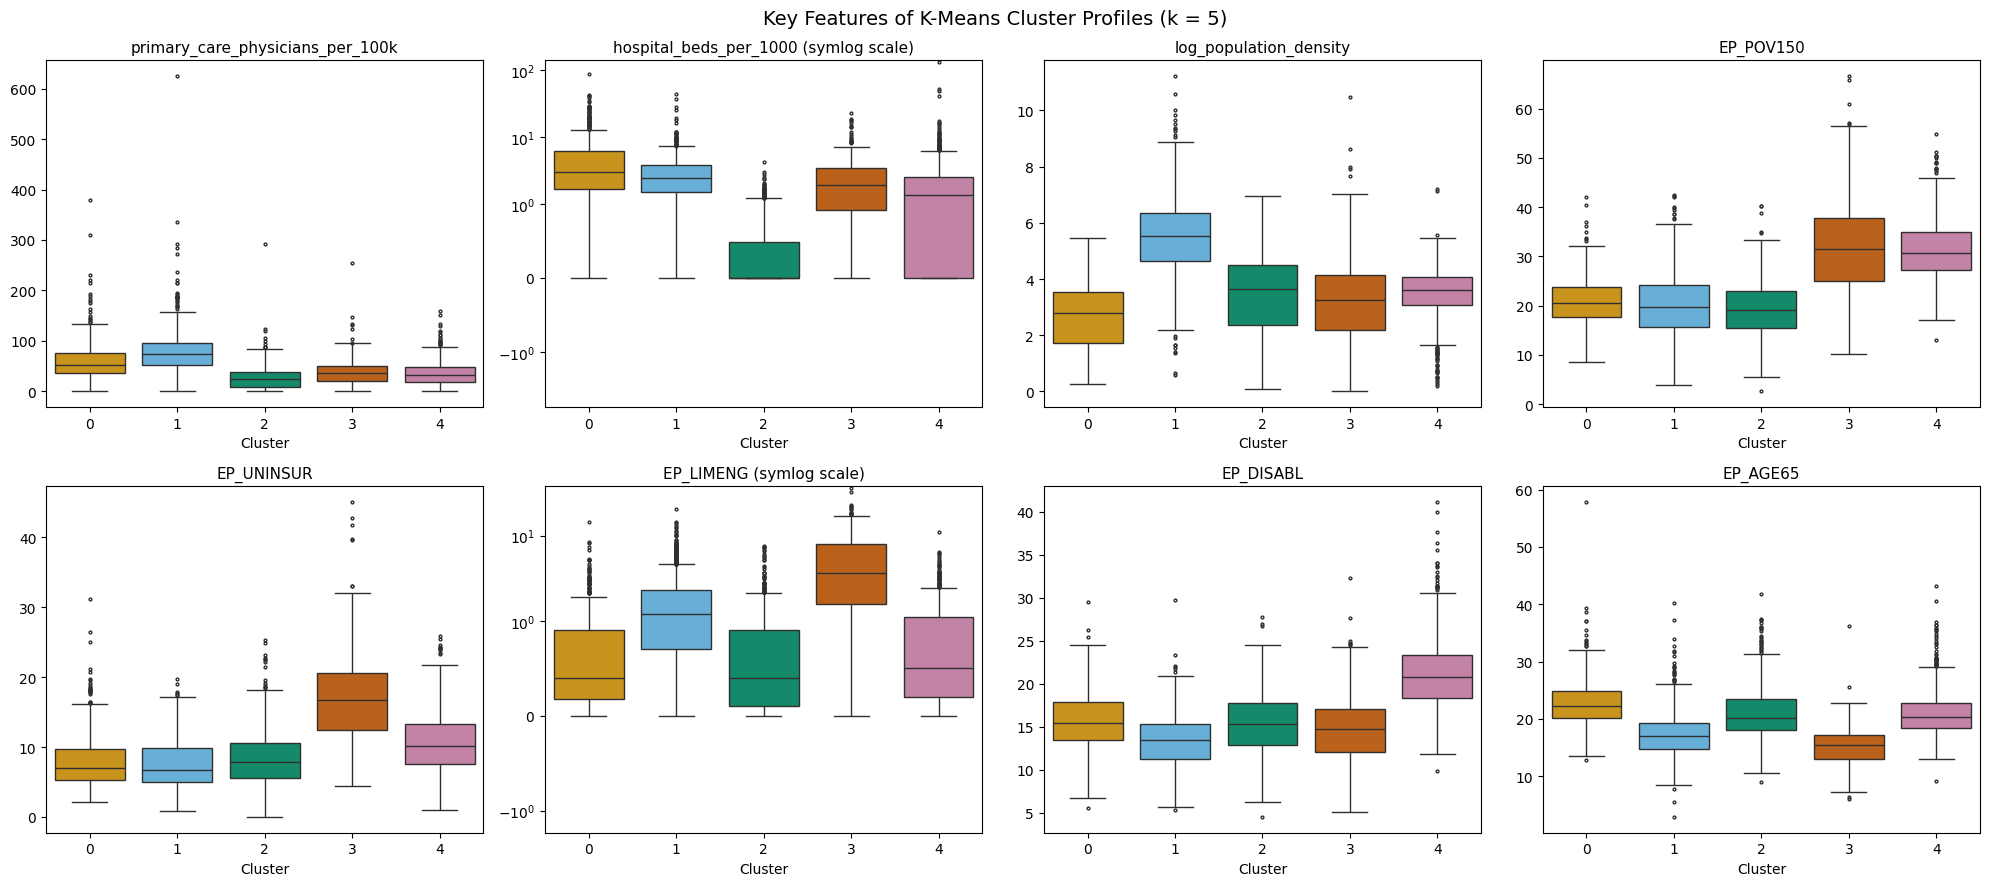

In [89]:
key_features = ["primary_care_physicians_per_100k", "hospital_beds_per_1000",
                "log_population_density", "EP_POV150",
                "EP_UNINSUR", "EP_LIMENG", "EP_DISABL", "EP_AGE65"]


def cluster_boxplots(label_col, palette, title):
    fig, axes = plt.subplots(2, 4, figsize=(20, 9))
    for ax, col in zip(axes.flat, key_features):
        sns.boxplot(data=cluster_base, x=label_col, y=col,
                    hue=label_col, legend=False,
                    palette=dict(enumerate(palette)), ax=ax, fliersize=2)
        ax.set_title(col, fontsize=11)
        ax.set_xlabel("Cluster")
        ax.set_ylabel("")
    for i in [1, 5]:
        axes.flat[i].set_yscale("symlog", linthresh=1)
        axes.flat[i].set_title(axes.flat[i].get_title() + " (symlog scale)", fontsize=11)
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()


cluster_boxplots("kmeans_cluster", palette, "Key Features of K-Means Cluster Profiles (k = 5)")
save_fig("kmeans_key_feature_boxplots.png")

The boxplots of these features visually show what separates the five clusters while also **reinforcing the low silhouette scores we saw earlier**. In other words, the clusters do have **distinct areas of feature variation**, but it's important to note that they **also lie on a continuum** where the clusters overlap. For instance, there is notable overlap on lower poverty across Clusters 0, 1, and 2 while it clearly becomes a defining feature of Clusters 3 and 4. What stands out most are:

- Cluster 0: oldest
- Cluster 1: highest on population density and PCPs 
- Cluster 2: lowest on hospital beds and PCPs
- Cluster 3: highest on uninsured, limited English, and poverty, and is the youngest 
- Cluster 4: highest on disability, with poverty similar to Cluster 3

## 5. Gaussian Mixture Models

### 5.1 Selecting Covariance Type & Number of Components

In [90]:
# consider silhouette score, Davies–Bouldin, AIC/BIC, stability, and substantive interpretability together rather than relying on one metric

gmm_results = []

for cov in ["spherical", "diag", "tied", "full"]:
    for k in range(2, 11):
        gmm = GaussianMixture(n_components=k, covariance_type=cov,
                              n_init=5, random_state=RANDOM_STATE).fit(X_final)
        labels = gmm.predict(X_final)
        gmm_results.append({
            "covariance": cov,
            "k": k,
            "BIC": gmm.bic(X_final), # lower is better
            "AIC": gmm.aic(X_final),
            "Silhouette": metrics.silhouette_score(X_final, labels),
            "Davies-Bouldin": metrics.davies_bouldin_score(X_final, labels),
            "converged": gmm.converged_
        })

gmm_df = pd.DataFrame(gmm_results)

save_table(gmm_df, "gmm_metrics_by_covariance.csv", decimals=3)

,covariance,k,BIC,AIC,Silhouette,Davies-Bouldin,converged
0,spherical,2,202638.656,202330.086,0.125,2.974,True
1,spherical,3,196940.978,196475.098,0.072,2.717,True
2,spherical,4,193342.707,192719.518,0.092,2.873,True
3,spherical,5,190240.917,189460.417,0.056,3.308,True
4,spherical,6,187475.470,186537.660,0.070,2.534,True
5,spherical,7,185384.692,184289.572,0.053,2.630,True
6,spherical,8,183996.930,182744.500,0.041,2.593,True
7,spherical,9,182924.403,181514.663,0.043,3.473,True
8,spherical,10,181915.410,180348.360,0.047,3.256,True
9,diag,2,200943.718,200356.830,0.123,2.657,True


**Covariance type: full**

- BIC values (about 137,000–140,000 for k ≥ 4) are far below the others. Tied is about 171,000, diagonal about 152,000 at best, and spherical about 182,000. In short, the data better supports clusters with their own tilted, stretched shapes. 

**Within full, number of components TBD:**

- Using full, there's a big drop from k = 3 to k = 4 in the BIC score (from 162,040 to 139,762). K = 4 through k = 7 is roughly flat, with k = 5 (139,369) being a local minimum in that range, but K = 9 is the lowest BIC overall (137,163). However, its silhouette score is also negative, implying that many counties are closer to another cluster than their own. We note, however, that full-covariance GMM makes stretched, irregular clusters on purpose, so Euclidean distance measures like silhouette and Davies-Bouldin are less compatible with the elliptical, probabilistic structure modeled by a full-covariance GMM. However, k = 9 cannot be entirely ruled out. We need to weight its global minimum BIC score against the negative silhouette score, interpretability, and stability.
- Below we'll look at whether k = 9 finds new and meaningful profiles or just models the tails. A full-covariance GMM may improve BIC scores by just adding small components that capture unusual outlier counties, improving fit without improving interpretable groups. We will check the cluster sizes at k = 5 versus k = 9. 

In [91]:
# GMM model for k = 5
gmm5 = GaussianMixture(n_components=5, covariance_type="full",
                       n_init=5, random_state=RANDOM_STATE).fit(X_final)
gmm_labels5 = gmm5.predict(X_final)

# GMM model for k = 9
gmm9 = GaussianMixture(n_components=9, covariance_type="full",
                       n_init=5, random_state=RANDOM_STATE).fit(X_final)
gmm_labels9 = gmm9.predict(X_final)

# compare cluster sizes for K-Means at k = 5 versus GMM at k = 5 and GMM at k = 9
def sorted_sizes(labels):
    s = pd.Series(labels).value_counts()          # sorted largest → smallest
    return [f"{n} ({n / len(labels):.1%})" for n in s]

sizes = {
    "K-means k=5": sorted_sizes(km5.labels_),
    "GMM k=5": sorted_sizes(gmm_labels5),
    "GMM k=9": sorted_sizes(gmm_labels9),
}

pd.DataFrame({name: pd.Series(v) for name, v in sizes.items()}).fillna("")

,K-means k=5,GMM k=5,GMM k=9
0,875 (27.9%),780 (24.9%),665 (21.2%)
1,743 (23.7%),708 (22.6%),607 (19.4%)
2,636 (20.3%),668 (21.3%),386 (12.3%)
3,565 (18.0%),632 (20.2%),376 (12.0%)
4,316 (10.1%),347 (11.1%),300 (9.6%)
5,,,258 (8.2%)
6,,,190 (6.1%)
7,,,188 (6.0%)
8,,,165 (5.3%)


All k = 9 components contained at least 5% of counties, suggesting that the model *may* add additional substructure rather than outlier modeling. We will 1) use a stability check using different seed values and 2) look at heat maps of the cluster profiles for both k = 5 and k = 9 and use interpretability criteria to make the final call.

### 5.2 Comparing Heat Map Cluster Profiles for GMM at k = 5 and k = 9

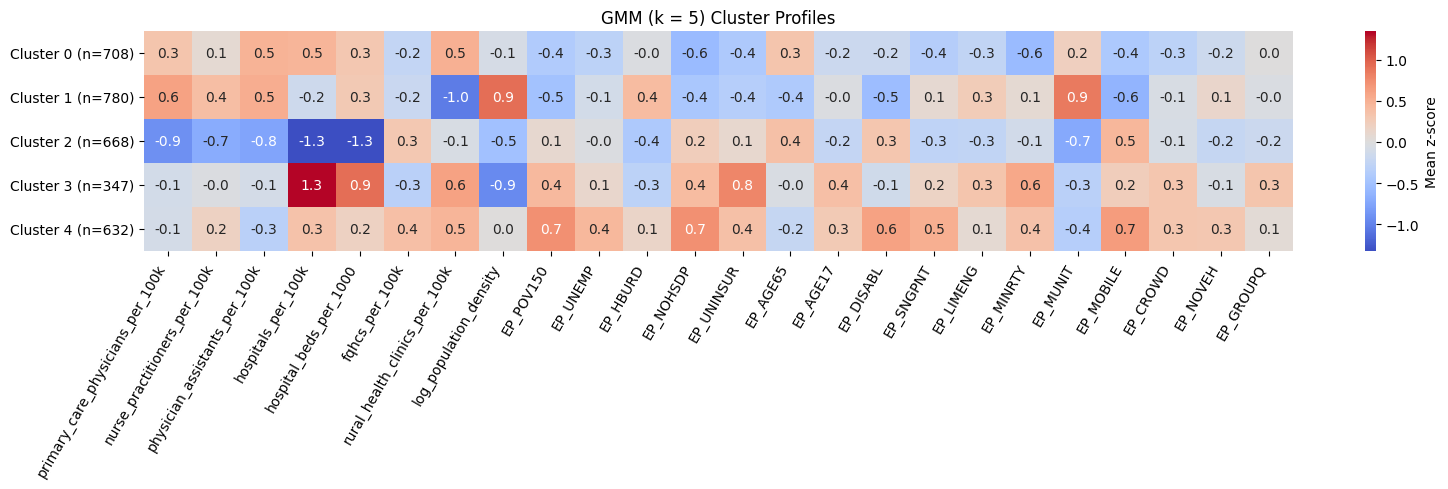

In [92]:
cluster_base["gmm5_cluster"] = gmm_labels5

cluster_profile_heatmap(gmm_labels5, "GMM (k = 5) Cluster Profiles")
save_fig("gmm5_cluster_profiles_heatmap.png")

Using the same standard in our evaluation of K-Means cluster profiles, we will treat features with |z| ≥ 0.5 as notably above average, and those with |z| ≥ 1.0 as defining characteristics.

**Cluster 0: Small-town/rural, moderately resourced, low-vulnerability** (n = 708)

- Most defining characteristics: n/a
- Notably above average: PAs (0.5), hospitals (0.5), rural health clinics (0.5)
- Notably below average: no diploma (−0.6), minority (−0.6)

**Cluster 1: Provider-rich, low-vulnerability, urban/suburban** (n = 780)

- Most defining characteristics: rural health clinics (−1.0)
- Notably above average: population density (0.9), multi-unit housing (0.9), PCPs (0.6), PAs (0.5)
- Notably below average: mobile homes (−0.6), poverty (−0.5), disability (−0.5)

**Cluster 2: Hospital and provider deserts** (n = 668)

- Most defining characteristics: hospitals (−1.3), hospital beds (−1.3)
- Notably above average: mobile homes (0.5)
- Notably below average: PCPs (−0.9), PAs (−0.8), NPs (−0.7), multi-unit housing (−0.7), population density (−0.5)

**Cluster 3: Remote rural, hospital-anchored, high uninsurance** (n = 347)

- Most defining characteristics: hospitals (1.3)
- Notably above average: hospital beds (0.9), uninsured (0.8), rural health clinics (0.6), minority (0.6)
- Notably below average: population density (−0.9)

**Cluster 4: Broad socioeconomic hardship** (n = 632)

- Most defining characteristics: n/a
- Notably above average: poverty (0.7), no high school diploma (0.7), mobile homes (0.7), disability (0.6), single parent (0.5), rural health clinics (0.5)
- Notably below average: n/a

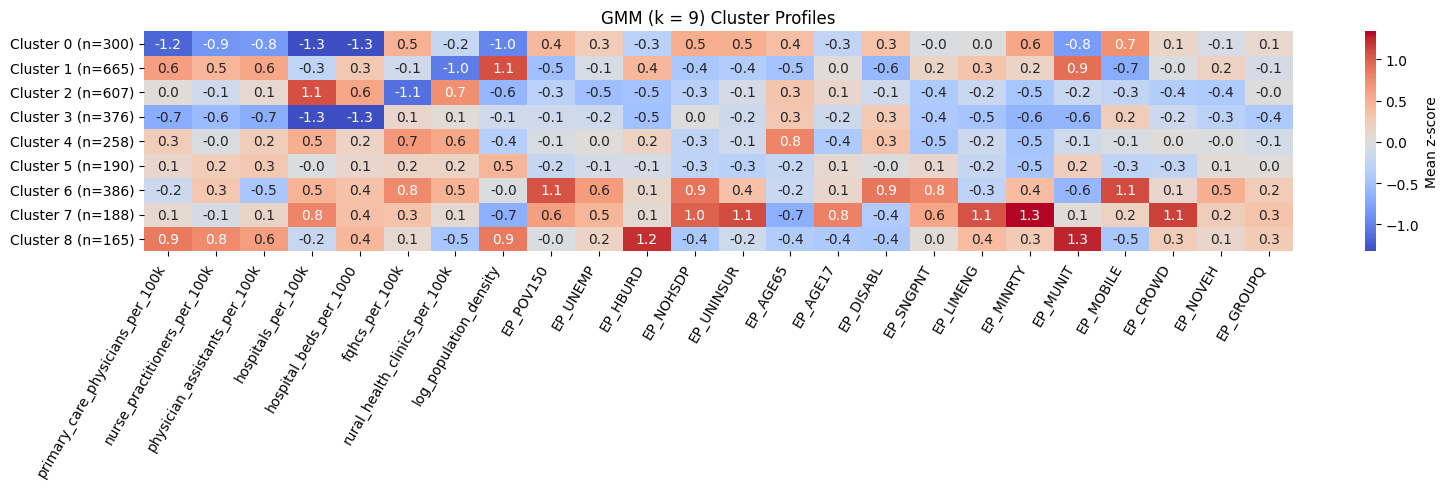

In [93]:
cluster_base["gmm9_cluster"] = gmm_labels9

cluster_profile_heatmap(gmm_labels9, "GMM (k = 9) Cluster Profiles")
save_fig("gmm9_cluster_profiles_heatmap.png")

Using the above criteria, k = 9 *may* be a clearer choice for more nuanced interpretability. Clusters 4 and 5 are fairly weak profiles in this version of GMM, however the additional nuance may be more applicable in a policy decision setting.

**Cluster 0: Rural healthcare deserts, social vulnerability** (n = 300)

- Most defining characteristics: hospitals (−1.3), hospital beds (−1.3), PCPs (−1.2), population density (−1.0)
- Notably above average: mobile homes (0.7), minority (0.6), FQHCs (0.5), no high school diploma (0.5), uninsured (0.5)
- Notably below average: NPs (−0.9), PAs (−0.8), multi-unit housing (−0.8)

**Cluster 1: Provider-rich, low-vulnerability, urban/suburban** (n = 665)

- Most defining characteristics: population density (1.1), rural health clinics (−1.0)
- Notably above average: multi-unit housing (0.9), PCPs (0.6), PAs (0.6), NPs (0.5)
- Notably below average: mobile homes (−0.7), disability (−0.6), poverty (−0.5), age 65+ (−0.5)

**Cluster 2: Rural, hospital-anchored, RHC-reliant, low-vulnerability** (n = 607)

- Most defining characteristics: hospitals (1.1), FQHCs (−1.1)
- Notably above average: rural health clinics (0.7), hospital beds (0.6)
- Notably below average: population density (−0.6), unemployment (−0.5), housing burden (−0.5), minority (−0.5)

**Cluster 3: Hospital-scarce, low-vulnerability** (n = 376)

- Most defining characteristics: hospitals (−1.3), hospital beds (−1.3)
- Notably above average: n/a
- Notably below average: PCPs (−0.7), PAs (−0.7), NPs (−0.6), minority (−0.6), multi-unit housing (−0.6), housing burden (−0.5), limited English (−0.5)

**Cluster 4: Older, facility-served** (n = 258)

- Most defining characteristics: n/a
- Notably above average: age 65+ (0.8), FQHCs (0.7), rural health clinics (0.6), hospitals (0.5)
- Notably below average: single parent (−0.5), minority (−0.5)

**Cluster 5: Near-average, mixed** (n = 190)

- Most defining characteristics: n/a
- Notably above average: population density (0.5)
- Notably below average: minority (−0.5)
- All other features within + or -0.3 of national average

**Cluster 6: Rural, high-hardship (poverty, disability), FQHC-reliant** (n = 386)

- Most defining characteristics: poverty (1.1), mobile homes (1.1)
- Notably above average: no diploma (0.9), disability (0.9), FQHCs (0.8), single parent (0.8), unemployment (0.6), hospitals (0.5), rural health clinics (0.5), no vehicle (0.5)
- Notably below average: multi-unit housing (−0.6), PAs (−0.5)

**Cluster 7: High access-barriers (uninsured/limited-English), young** (n = 188)

- Most defining characteristics: minority (1.3), uninsured (1.1), limited English (1.1), crowding (1.1), no diploma (1.0)
- Notably above average: hospitals (0.8), age 17 and under (0.8), poverty (0.6), single parent (0.6), unemployment (0.5)
- Notably below average: population density (−0.7), age 65+ (−0.7)

**Cluster 8: Dense urban, high housing cost burden, provider-rich** (n = 165)

- Most defining characteristics: multi-unit housing (1.3), housing cost burden (1.2)
- Notably above average: PCPs (0.9), population density (0.9), NPs (0.8), PAs (0.6)
- Notably below average: rural health clinics (−0.5), mobile homes (−0.5)

### 5.3 Stability Check for GMM at k = 5 and k = 9

In [94]:
for k in [5, 9]:
    base = GaussianMixture(n_components=k, covariance_type="full",
                           n_init=3, random_state=RANDOM_STATE).fit_predict(X_final)
    scores = []
    for seed in [1, 7, 21, 99, 123]:
        other = GaussianMixture(n_components=k, covariance_type="full",
                                n_init=3, random_state=seed).fit_predict(X_final)
        scores.append(adjusted_rand_score(base, other))
    print(f"k={k}: mean ARI across seeds = {np.mean(scores):.3f}  (min {np.min(scores):.3f})")

k=5: mean ARI across seeds = 0.955  (min 0.921)
k=9: mean ARI across seeds = 0.747  (min 0.578)


While the GMM model at k = 9 has the global minimum of BIC score and potentially offers more nuance for interpretability, it is only moderately stable across seeds with a mean ARI of .747 (minimum as low as .578). In contrast, the model is *highly* stable at k = 5 with a mean ARI of .955 (a high minimum of .921). Additionally two of the clusters at k = 9 are very weakly differentiated ("Older, facility-served” and "Near-average"). Weighing statistical fit (see 5.1) against stability, simplicity, and interpretability, and favoring direct comparability with the K-means solution, we selected k = 5 as the primary GMM solution.  

Given these tradeoffs, we will **treat the clusters from k = 9 as exploratory and worthy of future investigation but proceed with the model at k = 5**. Findings from clusters formed at k = 9 which may be worthy of future analysis include:
- Distinguishing between counties with a *double burden* of **healthcare resource scarcity and social vulnerability** versus those which are **just healthcare resource scarce** (Cluster 0 vs. Cluster 3; this vulnerability is averaged in Cluster 2 at k = 5)
- Distinguishing between urban counties with higher versus lower **housing costs** (Cluster 1 vs. Cluster 8)
- Distinguishing a clear **high access barriers** group in Cluster 7 that is dispersed between clusters at k = 5

### 5.4 Choropleth Map to Visualize GMM Cluster Profiles at k = 5

In [95]:
gmm_palette = cluster_palette.copy()
gmm_palette[3] = "#0072B2"   # other clusters are roughly K-Means counterparts except GMM 3 is not K-Means 3's counterpart

gmm_cluster_names = {
    0: "Small-town/rural, moderate resources",
    1: "Urban/suburban, provider-rich",
    2: "Hospital and provider deserts",
    3: "Remote rural, hospital-served, uninsured",
    4: "Broad socioeconomic hardship",                                                       
} 

gm_choropleth = choropleth_map("gmm5_cluster", gmm_cluster_names, gmm_palette,
                 "County Healthcare Access and Social Vulnerability Profiles (GMM, k = 5)")

save_map_html(gm_choropleth, "map_gmm_k5.html")

# Interactive map saved to figures/unsupervised/map_gmm_k5.html

Saved interactive map to ../figures/unsupervised/map_gmm_k5.html


### 5.5 Boxplots of Key Features Separating Cluster Profiles

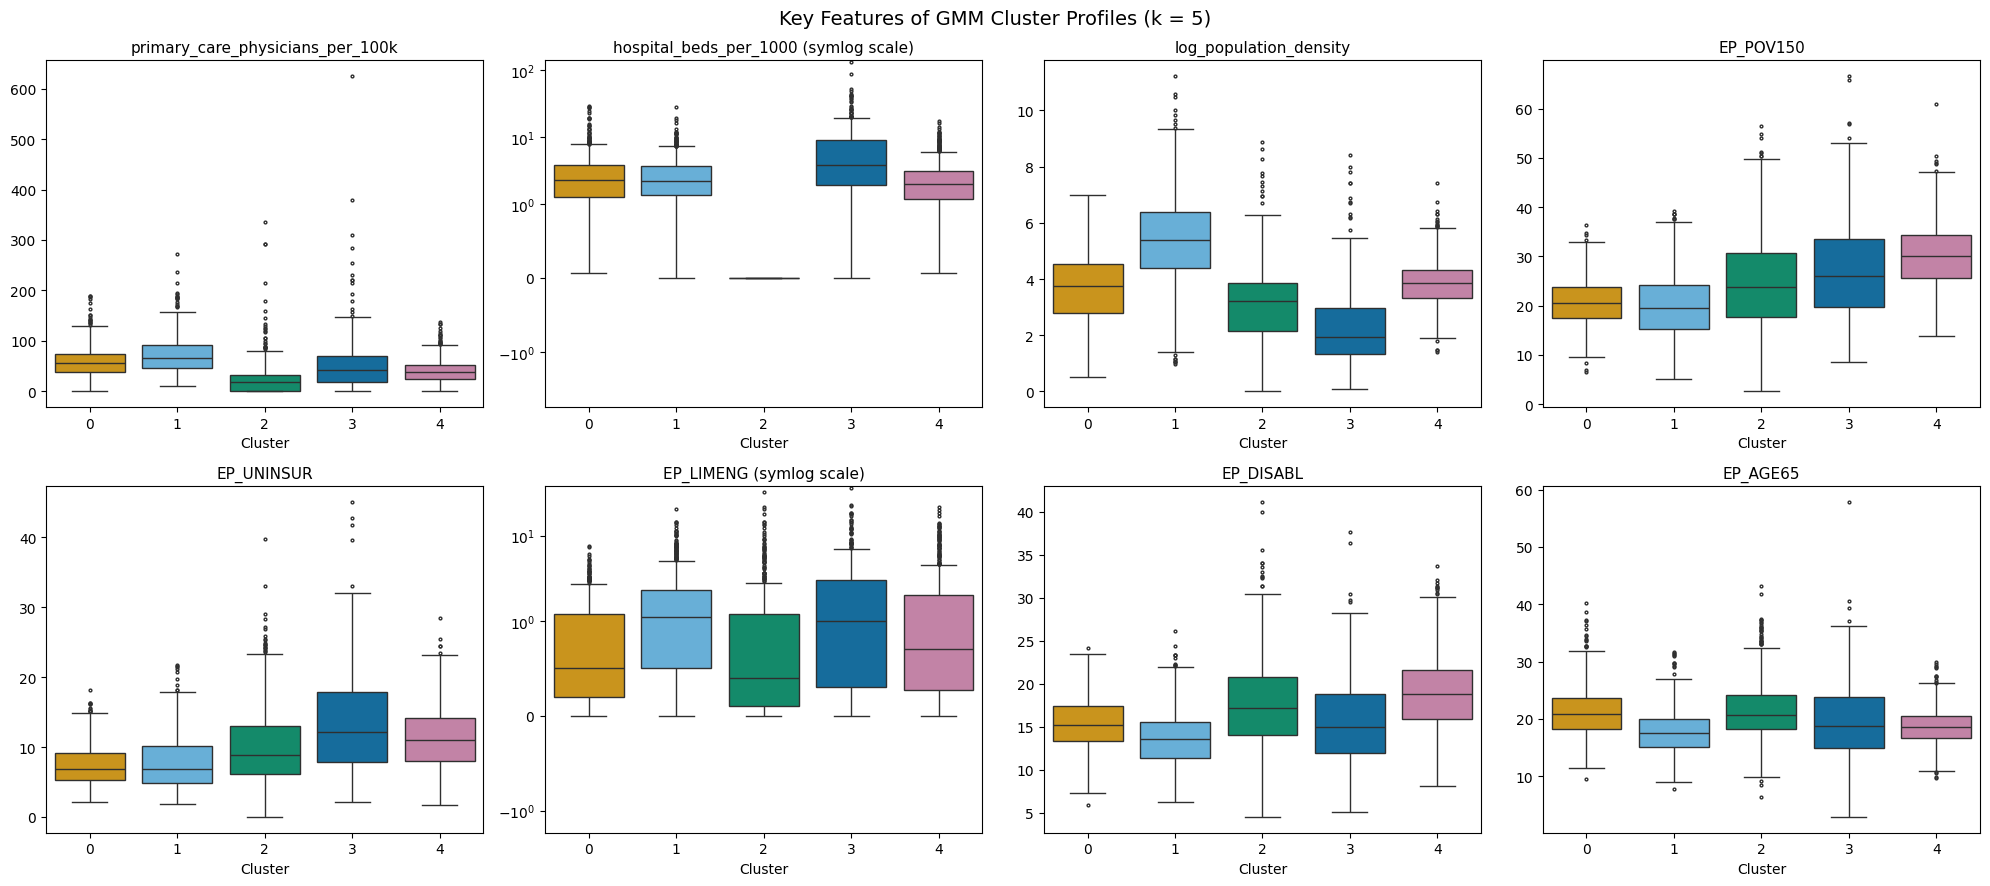

In [96]:
cluster_boxplots("gmm5_cluster", gmm_palette, "Key Features of GMM Cluster Profiles (k = 5)")
save_fig("gmm5_key_feature_boxplots.png")

...

### 5.6 GMM Assignment Uncertainty

In [97]:
gmm_proba = gmm5.predict_proba(X_final)  # one probability per component
cluster_base["gmm5_max_prob"] = gmm_proba.max(axis=1)

max_prob = cluster_base["gmm5_max_prob"]
pd.DataFrame({
    "share of counties": [
        (max_prob >= 0.9).mean(),
        ((max_prob >= 0.7) & (max_prob < 0.9)).mean(),
        (max_prob < 0.7).mean(),
    ]
}, index=["confident (≥ 0.9)", "moderate (0.7–0.9)", "uncertain (< 0.7)"]).round(3)

,share of counties
confident (≥ 0.9),0.941
moderate (0.7–0.9),0.039
uncertain (< 0.7),0.020


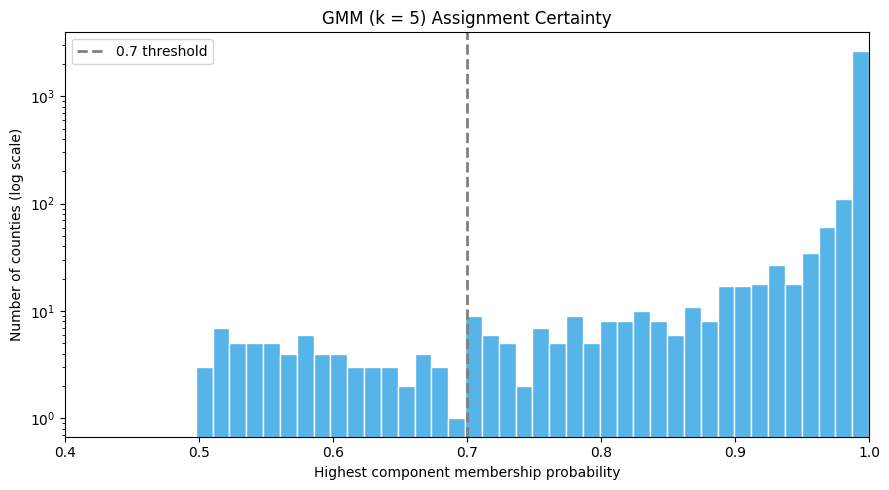

In [98]:
plt.figure(figsize=(9, 5))
plt.hist(max_prob, bins=40, color="#56B4E9", edgecolor="white")
plt.axvline(0.7, color="gray", linestyle="--", linewidth=2, label="0.7 threshold")
plt.xlabel("Highest component membership probability")
plt.ylabel("Number of counties (log scale)")
plt.title("GMM (k = 5) Assignment Certainty")
plt.legend()
plt.xlim(0.4, 1.0)
plt.yscale("log")
plt.tight_layout()
save_fig("gmm_k5_assignment_certainty.png")

In [99]:
(cluster_base.groupby("gmm5_cluster")["gmm5_max_prob"]
 .agg(median="median", share_uncertain=lambda p: (p < 0.7).mean())
 .rename(index=gmm_cluster_names)
 .round(2))

,median,share_uncertain
gmm5_cluster,,
"Small-town/rural, moderate resources",1.0,0.02
"Urban/suburban, provider-rich",1.0,0.00
Hospital and provider deserts,1.0,0.00
"Remote rural, hospital-served, uninsured",1.0,0.04
Broad socioeconomic hardship,1.0,0.05


GMM membership probabilities were highly concentrated: 94.1% of counties had a maximum component probability of at least 0.9, 3.9% fell between 0.7 and 0.9, and only 2.0% fell below 0.7. The few uncertain assignments were concentrated in the “broad socioeconomic hardship” (5%) and “remote rural, hospital-served, uninsured” (4%) components, the two least sharply defined profiles. However, this should not be read as evidence of well-separated clusters. Full-covariance mixture models fit in high-dimensional feature spaces are likely to be assigned decisively to one component even when components overlap. Low silhouette scores, moderate agreement with K-Means (ARI = 0.29), and sensitivity to alternative specifications all indicate that county profiles lie along a continuum. Assignment certainty is more reflective of the model’s internal confidence rather than the degree of real separation between county types.

## 6. Comparing K-Means and GMM and Selecting a Primary Model

### 6.1 Crosstab of Both Models' Clusters

In [100]:
pd.crosstab(pd.Series(km5.labels_, name="K-means"),
            pd.Series(gmm_labels5, name="GMM k=5"))

GMM k=5,0,1,2,3,4
K-means,,,,,
0,390,60,1,149,36
1,203,571,18,34,49
2,55,74,391,2,43
3,4,26,42,109,135
4,56,49,216,53,369


### 6.2 Both Models Side-by-Side in PCA Space

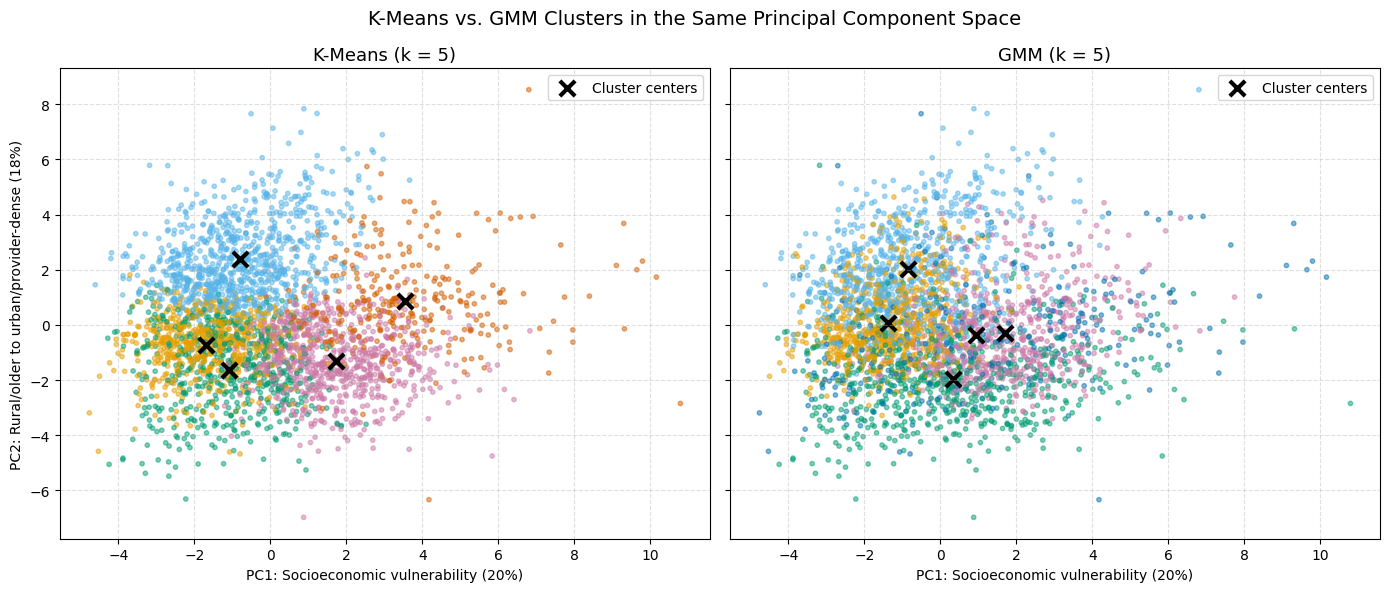

In [101]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

for ax, (labels, centers, pal, title) in zip(axes, [
    (km5.labels_,  km5.cluster_centers_, cluster_palette, "K-Means (k = 5)"),
    (gmm_labels5,  gmm5.means_,          gmm_palette,     "GMM (k = 5)"),
]):
    centers_2d = pca_2d.transform(centers)
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=np.array(pal)[labels], s=10, alpha=0.5)
    ax.scatter(centers_2d[:, 0], centers_2d[:, 1], c="black", marker="x", s=120,
               linewidths=3, label="Cluster centers")
    ax.set_title(title, fontsize=13)
    ax.set_xlabel(f"PC1: Socioeconomic vulnerability ({pca_2d.explained_variance_ratio_[0]:.0%})")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(loc="upper right")

axes[0].set_ylabel(f"PC2: Rural/older to urban/provider-dense ({pca_2d.explained_variance_ratio_[1]:.0%})")
plt.suptitle("K-Means vs. GMM Clusters in the Same Principal Component Space", fontsize=14)
plt.tight_layout()
save_fig("pca_scatter_kmeans_vs_gmm5.png")

Both methods partition the same continuous cloud of counties. K-Means divides it into more compact regions, whereas GMM’s full-covariance components follow correlations in dimensions beyond the first two principal components and therefore appear less separated in a PCA projection in general.

### 6.3 Comparison Table, Analysis, and Selection of Primary Model

In [102]:
# agreement of the two k = 5 solutions
print("ARI, K-means vs. GMM (k = 5):",
      round(adjusted_rand_score(km5.labels_, gmm_labels5), 3))

# side-by-side summary of the two candidate models
model_comparison = pd.DataFrame({
    "K-Means (k = 5)": {
        "Key selection criteria": "Davies-Bouldin min; silhouette local max; elbow",
        "Silhouette": round(metrics.silhouette_score(X_final, km5.labels_), 3),
        "Stability (mean ARI across seeds)": 0.992,
        "Stability (min ARI)": 0.984,
        "Clusters with a defining feature (|z| ≥ 1.0)": "5 of 5",
        "Robust to adding HPSA flags": "Moderately (ARI 0.40, balanced clusters)",
    },
    "GMM (full, k = 5)": {
        "Key selection criteria": "BIC local min after elbow",
        "Silhouette": round(metrics.silhouette_score(X_final, gmm_labels5), 3),
        "Stability (mean ARI across seeds)": 0.955,
        "Stability (min ARI)": 0.921,
        "Clusters with a defining feature (|z| ≥ 1.0)": "3 of 5",
        "Robust to adding HPSA flags": "No (ARI 0.03, degenerate solution)",
    },
})
save_table(model_comparison, "model_comparison_kmeans_gmm.csv")

ARI, K-means vs. GMM (k = 5): 0.292


,K-Means (k = 5),"GMM (full, k = 5)"
Key selection criteria,Davies-Bouldin min; silhouette local max; elbow,BIC local min after elbow
Silhouette,0.123,0.023
Stability (mean ARI across seeds),0.992,0.955
Stability (min ARI),0.984,0.921
Clusters with a defining feature (|z| ≥ 1.0),5 of 5,3 of 5
Robust to adding HPSA flags,"Moderately (ARI 0.40, balanced clusters)","No (ARI 0.03, degenerate solution)"


K-Means and GMM models at k = 5 showed moderate agreement (ARI = 0.29). The crosstab in 6.1 shows which profiles both methods recover and which they draw differently:

**Recovered by both models:** 
- urban/suburban, provider-rich counties (K-Means 1 maps to GMM 1; 571 of 875 counties, 65%)
- resource-scarce counties (K-Means 2 maps to GMM 2; 391 of 565, 69%)
- rural hospital-anchored counties (K-Means 0 maps to GMM 0; 390 of 636, 61%)

**Partially recovered:**
- rural high-hardship counties (K-Means 4 maps to GMM 4; 369 of 743, 50%; another 216 went to GMM’s “hospital and provider deserts”)

**Method-dependent:** 
- K-Means high-access-barrier cluster (K-Means 3) has no GMM counterpart. Its counties split mainly between GMM 4 (135) and GMM 3 (109)

The profiles that both methods recover are the most robust findings of this analysis. Boundaries among high-vulnerability profiles depend on the method, consistent with the continuum-like structure indicated by low silhouette scores.

**Primary model: K-Means (k = 5)** 

We selected K-Means as the primary unsupervised model for four reasons:

- **Stability:** It reproduced nearly identical solutions across random seeds (mean ARI = 0.992 vs. 0.955 for GMM)
- **Interpretability:** All five K-Means clusters have at least one defining feature (|z| ≥ 1.0), while two of the five GMM clusters (“small-town/rural, moderate resources” and “broad socioeconomic hardship”) have none
- **Evaluation fit:** K-Means can be assessed directly with distance-based metrics (silhouette, Davies-Bouldin, Calinski-Harabasz), whereas these metrics understate the quality of full-covariance GMMs
- **Robustness:** Adding the HPSA flags shifted K-Means boundaries moderately but left clusters balanced, while the GMM produced a degenerate solution (see 7.1 below)

GMM (k = 5) is retained as a comparison model, and results for both are reported in sections 6 and 7. GMM (k = 9) remains an exploratory solution (see 5.3).

### 6.4 Sensitivity Check: Equal Domain Weighting

In [103]:
# rebalance domains: scale the 16 SVI columns so their total weight equals the 8 resource columns

w = np.ones(len(continuous))
svi_idx = [continuous.index(c) for c in unsupervised_svi_features]
w[svi_idx] = np.sqrt(len(unsupervised_resource_features) / len(unsupervised_svi_features))

X_weighted = X_final * w

km_weighted = KMeans(n_clusters=5, n_init=20, random_state=RANDOM_STATE).fit_predict(X_weighted)

print("ARI, K-Means equal-domain vs. primary:", round(adjusted_rand_score(km5.labels_, km_weighted), 3))
print("Cluster sizes (equal-domain):", np.bincount(km_weighted))

# crosstab: where primary clusters went under equal domain weighting
domain_ct = pd.crosstab(pd.Series(km5.labels_, name="K-Means primary"),
                        pd.Series(km_weighted, name="Equal-domain cluster"))
domain_ct.index = domain_ct.index.map(km_cluster_names)

save_table(domain_ct, "sensitivity_domain_weighting_crosstab.csv", decimals=0)

ARI, K-Means equal-domain vs. primary: 0.364
Cluster sizes (equal-domain): [670 942 441 500 582]


Equal-domain cluster,0,1,2,3,4
K-Means primary,,,,,
"Rural, older, hospital-anchored",1,195,0,440,0
"Urban/suburban, provider-rich",6,457,410,1,1
"Resource-scarce, low-vulnerability",0,169,0,8,388
"High access barriers, young",245,8,30,18,15
"High-hardship, FQHC-reliant",418,113,1,33,178


As an additional sensitivity analysis, we reweighted the 16 SVI features so the social-vulnerability and healthcare-resource domains contributed equally to distances. Cluster assignments shifted moderately (ARI = 0.36 with the primary solution). The crosstab shows that the broad structure stayed consistent: most rural hospital-anchored counties (440 of 636) and resource-scarce counties (388 of 565) remained grouped together. The main change was that the two high-vulnerability profiles, “high access barriers, young” and “rural high-hardship,” largely merged into a single cluster (245 of 316 and 418 of 743 counties, respectively), while urban/suburban provider-rich counties split into two clusters. 

Domain weighting therefore materially **affects cluster assignments, particularly the distinction between types of social vulnerability**. We **retain the equally weighted 24-feature solution** as the primary analysis because it **preserves distinctions among vulnerability subtypes that equal domain weighting collapses**. 

## 7. Evaluation Using HPSA Designations 

### 7.1 Sensitivity Check Using HPSA Designations & Sensitivity Summary

How different would the clusters have been if the binary HPSA flags were included?

In [104]:
X_hpsa = prep(continuous + unsupervised_hpsa_features)
km_hpsa = KMeans(n_clusters=5, n_init=20, random_state=RANDOM_STATE).fit_predict(X_hpsa)
print("ARI, K-means with vs. without HPSA:", round(adjusted_rand_score(km5.labels_, km_hpsa), 3))

ARI, K-means with vs. without HPSA: 0.403


In [105]:
gmm_hpsa = GaussianMixture(n_components=5, covariance_type="full",
                           n_init=3, random_state=RANDOM_STATE).fit_predict(X_hpsa)

print("ARI, GMM with vs. without HPSA:", round(adjusted_rand_score(gmm_labels5, gmm_hpsa), 3))

ARI, GMM with vs. without HPSA: 0.028


Use a crosstab to check why the ARI dropped so low:

In [106]:
hpsa_pattern = (cluster_base[unsupervised_hpsa_features]
                .astype(int).astype(str).agg("".join, axis=1))
hpsa_pattern.name = "HPSA pattern (PC, MH, Dental)"

print("GMM with HPSA sizes:", np.bincount(gmm_hpsa))
pd.crosstab(pd.Series(gmm_hpsa, name="GMM with HPSA"), hpsa_pattern)

GMM with HPSA sizes: [1942  174  195  371  453]


"HPSA pattern (PC, MH, Dental)",000,001,010,011,100,101,110,111
GMM with HPSA,,,,,,,,
0,66,11,104,41,36,65,272,1340
1,5,4,16,7,16,5,26,94
2,15,4,14,3,8,9,27,115
3,23,5,41,23,10,5,50,213
4,17,5,22,15,5,17,106,266


In [107]:
print("K-means with HPSA sizes:", np.bincount(km_hpsa))
pd.crosstab(pd.Series(km_hpsa, name="K-means with HPSA"), hpsa_pattern)

K-means with HPSA sizes: [656 458 593 525 903]


"HPSA pattern (PC, MH, Dental)",000,001,010,011,100,101,110,111
K-means with HPSA,,,,,,,,
0,22,8,31,23,12,20,86,450
1,27,6,45,14,15,10,71,268
2,24,3,31,15,12,19,86,401
3,19,3,32,14,15,15,86,340
4,34,9,58,23,21,37,152,569


Adding the three HPSA designation flags to the clustering matrix substantially altered assignments (ARI for K-means: 0.403; ARI for GMM: 0.028). For K-Means, the clusters remained balanced in size (458–903 counties) and were not organized by designation pattern. I.e., many counties moved between clusters, but the new clusters were not defined by HPSA status, consistent with the continuum-like structure indicated by low silhouette scores. For GMM, inclusion produced a degenerate solution in which one component contained 1,942 counties (62%). Given the limited variability (72–89% of counties designated) and poor compatibility of binary variables with Gaussian mixture models, HPSA flags were retained for cluster profiling rather than cluster construction. This was a modeling decision, not a finding that their inclusion is inconsequential.

In [108]:
sensitivity_summary = pd.DataFrame([
    {"Check": "Seed stability (5 reruns)", "Model": "K-Means k = 5", "ARI vs. primary": 0.992,
     "Interpretation": "Highly stable"},
    {"Check": "Seed stability (5 reruns)", "Model": "GMM k = 5", "ARI vs. primary": 0.955,
     "Interpretation": "Highly stable"},
    {"Check": "Seed stability (5 reruns)", "Model": "GMM k = 9", "ARI vs. primary": 0.747,
     "Interpretation": "Moderately stable; treated as exploratory"},
    {"Check": "Add HPSA flags", "Model": "K-Means k = 5",
     "ARI vs. primary": adjusted_rand_score(km5.labels_, km_hpsa),
     "Interpretation": "Boundaries shift; clusters stay balanced"},
    {"Check": "Add HPSA flags", "Model": "GMM k = 5",
     "ARI vs. primary": adjusted_rand_score(gmm_labels5, gmm_hpsa),
     "Interpretation": "Degenerate (one component with 62% counties)"},
    {"Check": "Equal domain weighting", "Model": "K-Means k = 5",
     "ARI vs. primary": adjusted_rand_score(km5.labels_, km_weighted),
     "Interpretation": "Broad structure kept; vulnerability subtypes merge"},
])

save_table(sensitivity_summary, "sensitivity_summary.csv", decimals=3)

,Check,Model,ARI vs. primary,Interpretation
0,Seed stability (5 reruns),K-Means k = 5,0.992,Highly stable
1,Seed stability (5 reruns),GMM k = 5,0.955,Highly stable
2,Seed stability (5 reruns),GMM k = 9,0.747,Moderately stable; treated as exploratory
3,Add HPSA flags,K-Means k = 5,0.403,Boundaries shift; clusters stay balanced
4,Add HPSA flags,GMM k = 5,0.028,Degenerate (one component with 62% counties)
5,Equal domain weighting,K-Means k = 5,0.364,Broad structure kept; vulnerability subtypes m...


### 7.2 Profiling Clusters Using HPSA Designations

In [109]:
def hpsa_profile(label_col, names):
    out = (cluster_base.groupby(label_col)[unsupervised_hpsa_features]
           .mean().mul(100).round(1))
    out.index = out.index.map(names)
    out.columns = ["% Primary Care HPSA", "% Mental Health HPSA", "% Dental HPSA"]
    return out

save_table(hpsa_profile("kmeans_cluster", km_cluster_names), "hpsa_rates_kmeans_k5.csv", decimals=1)

,% Primary Care HPSA,% Mental Health HPSA,% Dental HPSA
kmeans_cluster,,,
"Rural, older, hospital-anchored",85.4,95.1,68.7
"Urban/suburban, provider-rich",72.8,76.3,59.7
"Resource-scarce, low-vulnerability",86.4,89.7,65.0
"High access barriers, young",96.5,96.8,79.4
"High-hardship, FQHC-reliant",96.8,96.0,90.8


In [110]:
save_table(hpsa_profile("gmm5_cluster", gmm_cluster_names), "hpsa_rates_gmm_k5.csv", decimals=1)

,% Primary Care HPSA,% Mental Health HPSA,% Dental HPSA
gmm5_cluster,,,
"Small-town/rural, moderate resources",87.0,90.4,69.8
"Urban/suburban, provider-rich",69.6,76.9,56.4
Hospital and provider deserts,90.4,92.5,76.3
"Remote rural, hospital-served, uninsured",91.6,96.5,79.5
Broad socioeconomic hardship,96.7,95.9,84.2


Across the clustering analysis sample, designation rates were are 85.8% primary care, 89.0% mental health, and 71.6% dental. Across both methods, urban/provider-rich counties have the lowest designation rates on all three types (about 70–77% primary care and mental health, 56–60% dental) and hardship and high-barrier clusters have the highest (about 96% primary care and mental health). Rural high-hardship counties in K-Means reach 90.8% dental, the highest in either table, while the K-Means cluster 2 with the lowest provider and hospital supply had low social vulnerability and showed only average designation rates (primary care 86%, dental 65%). In short, HPSA designation rates were higher in several high-vulnerability/high-barrier profiles than in the low-provider-supply profile, **suggesting that HPSA status captures an access dimension not represented by provider supply alone**. Lower provider *supply* doesn’t singularly translate into more shortage designations. Dental designation is what varied most across clusters (56–91%).

## 8. Comparing Outcome (PLACES Routine-Checkup Prevalence) Across Clusters for K-Means and GMM

### 8.1 Merge Outcome Variable With Cluster Assignments on FIPS Codes

In [111]:
outcome_df = cluster_base[["fips", "kmeans_cluster", "gmm5_cluster"]].merge(
    shared_analytical[["fips", target_col]], on="fips", how="left"
)

print(outcome_df.shape) 
outcome_df.head()

(3135, 4)


,fips,kmeans_cluster,gmm5_cluster,routine_checkup_pct
0,06045,4,0,68.6
1,02063,1,2,62.2
2,04007,4,4,68.8
3,05087,2,2,74.5
4,05067,4,4,76.7


### 8.2 Summary Tables and Boxplots of Checkup Prevalence by Cluster for K-Means and GMM at k = 5

In [112]:
def outcome_summary(label_col, names):
    grouped = outcome_df.groupby(label_col)[target_col]
    out = pd.DataFrame({
        "n": grouped.size(),
        "median": grouped.median(),
        "Q1": grouped.quantile(0.25),
        "Q3": grouped.quantile(0.75),
        "mean": grouped.mean(),
    }).round(1)
    out.index = out.index.map(names)
    return out

print("National Median:", round(outcome_df[target_col].median(), 1))

save_table(outcome_summary("kmeans_cluster", km_cluster_names), "outcome_summary_kmeans_k5.csv", decimals=1)

National Median: 74.4


,n,median,Q1,Q3,mean
kmeans_cluster,,,,,
"Rural, older, hospital-anchored",636,73.1,70.2,74.8,72.4
"Urban/suburban, provider-rich",875,75.5,72.8,77.0,74.6
"Resource-scarce, low-vulnerability",565,73.9,71.5,75.7,73.4
"High access barriers, young",316,71.6,70.0,75.1,72.2
"High-hardship, FQHC-reliant",743,75.7,73.6,77.4,75.1


In [113]:
save_table(outcome_summary("gmm5_cluster", gmm_cluster_names), "outcome_summary_gmm_k5.csv", decimals=1)

,n,median,Q1,Q3,mean
gmm5_cluster,,,,,
"Small-town/rural, moderate resources",708,73.9,71.0,75.4,73.1
"Urban/suburban, provider-rich",780,75.3,72.9,76.9,74.6
Hospital and provider deserts,668,74.2,71.7,76.2,73.7
"Remote rural, hospital-served, uninsured",347,71.5,68.9,74.4,71.7
Broad socioeconomic hardship,632,75.3,72.8,77.4,74.9


NameError: name 'national_median' is not defined

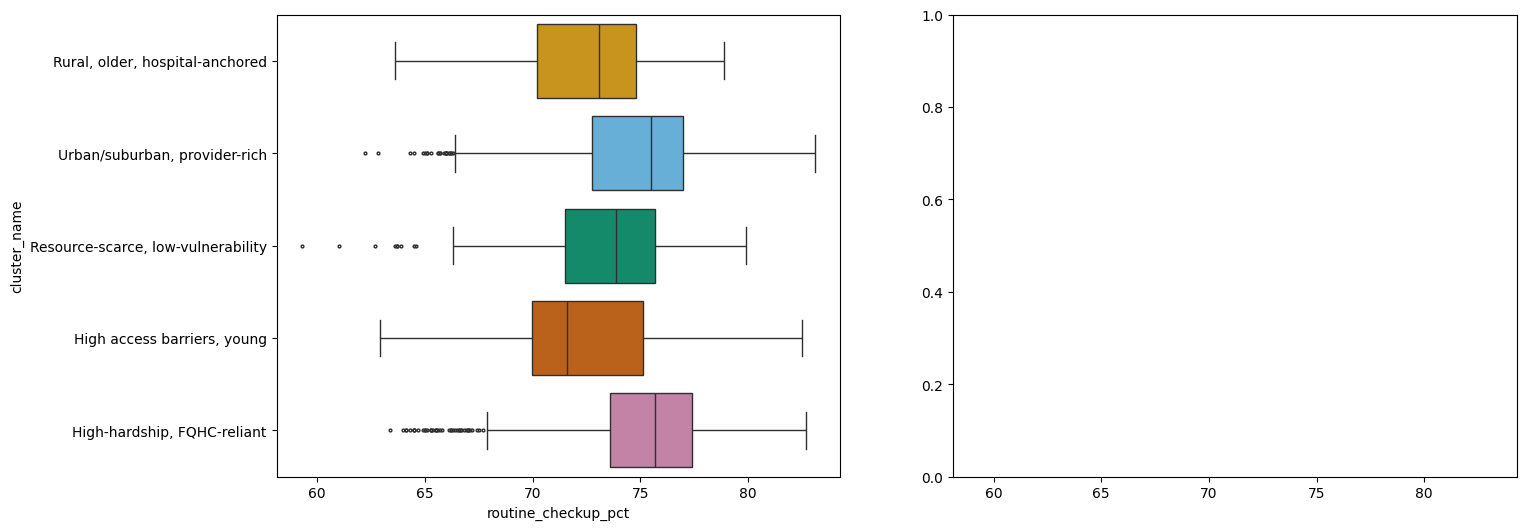

In [114]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
analysis_smpl_median = outcome_df[target_col].median()

for ax, (col, names, pal, title) in zip(axes, [
    ("kmeans_cluster", km_cluster_names, cluster_palette, "K-Means (k = 5)"),
    ("gmm5_cluster", gmm_cluster_names, gmm_palette, "GMM (k = 5)"),
]):
    plot_df = outcome_df.assign(cluster_name=outcome_df[col].map(names))
    order = [names[i] for i in sorted(names)]
    sns.boxplot(data=plot_df, x=target_col, y="cluster_name",
                hue="cluster_name", legend=False, order=order,
                palette={names[i]: pal[i] for i in names},
                ax=ax, fliersize=2)
    ax.axvline(analysis_smpl_median, color="gray", linestyle="--", linewidth=2,
               label=f"Analysis-sample Median: ({national_median:.1f}%)")
    ax.set_title(title)
    ax.set_xlabel("Routine checkup prevalence (%, age-adjusted)")
    ax.set_ylabel("")

axes[0].legend(loc="lower left")   # one legend is enough; the line means the same thing in both panels

plt.suptitle("Routine Checkup Prevalence by Cluster", fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "outcome_boxplots_kmeans_gmm_k5.png", dpi=300, bbox_inches="tight")

**1. Cluster medians show modest differences and IQRs overlap considerably:**
- Cluster medians span about 4 percentage points (71.5-75.7%). Cluster membership is associated with checkup rates but it doesn't strongly separate clusters. As stated previously, clusters lie much more on a continuum rather than being strongly delineated. 
  
**2. The lowest checkup rates are in the healthcare access-barrier clusters under both models:**
- For K-Means, the "High access barriers, young" cluster had a 71.6% median while GMM's "Remote rural, hospital-served, uninsured" cluster had a 71.5% median.
- Importantly (see crosstab above) these clusters contain largely different counties, but their key commonality is **high rates of uninsurance**.

**3. High-hardship clusters did not have lower checkup prevalence:**
- K-Means' "Rural high-hardship, FQHC-reliant" cluster has the highest median at 75.7%, just slightly above the "Urban/suburban, provider-rich" cluster at 75.3%. GMM's comparable clusters have a tie at 75.5% for both ("Urban/suburban, provider-rich" and "Broad socioeconomic hardship"). Further research would be needed here. For instance, one hypothesis for future investigation would be whether a higher burden of chronic disease is associated with a higher prevalence of routine care in some areas or if there are other regional patterns at play.

**4. Provider-scarce clusters had checkup prevalence near the 3,135 county median:**
- The "Resource-scarce, low-vulnerability" cluster from K-Means and "Hospital and provider deserts" cluster from GMM have medians closest to the national median (73.9% and 74.2% respectively) despite notably lower provider supply.

To summarize, within the identified profiles, lower routine-checkup prevalence tended to occur in clusters characterized by high uninsurance and related access barriers, rather than in clusters defined by healthcare-resource scarcity alone. However, checkup prevalence distributions overlap considerably across clusters (median range 71.5–75.7%, with substantial IQR overlap), so cluster membership captures only modest differences in utilization, and many counties in every profile fall near the 3,135 county median. These patterns are descriptive associations at the county level and should not be interpreted as evidence that uninsurance or any other profile characteristic causes lower checkup prevalence.

## 9. Save Final Cluster Assignments and Summary

In [115]:
# save final cluster labels for teammates (one row per clustered county w/ CT excluded)

cluster_base[["fips", "state_abbr", "county_name_places",
              "kmeans_cluster", "gmm5_cluster"]].to_csv(
    TABLE_DIR / "cluster_assignments.csv", index=False)

Clustering 3,135 U.S. counties on 24 healthcare-resource and social-vulnerability features showed that **counties do not fall into sharply separated types but rather lie along a continuum**; clusters are best read as recognizable profiles within it. Silhouette scores were low at every k (about 0.08–0.15), and the first two principal components (38% of variance) showed a continuous cloud of counties organized along two largely independent axes: socioeconomic vulnerability (PC1) and an urban/provider-rich versus rural/older gradient (PC2). 

Two clustering methods, K-Means and Gaussian mixture models (GMM), agreed on part of the structure and differed on the rest (ARI = 0.29). **Both models recovered urban, provider-rich counties and provider-scarce counties as distinct groups but divided high-vulnerability counties differently**. K-Means separated a young, uninsured, limited-English profile from an older profile marked by disability and poverty. GMM instead identified a remote rural, hospital-served, high-uninsurance group alongside a broad hardship group, and its 9-component solution pointed to a “double burden” subgroup of counties with both scarce providers and high vulnerability. The most surprising finding was that **healthcare-resource scarcity and social vulnerability did not move together**. The most provider- and hospital-scarce K-Means cluster had low social vulnerability and HPSA shortage designations followed vulnerability more closely than provider supply: the resource-scarce cluster showed near-average designation rates (86% primary care, 65% dental), while the high-hardship cluster reached 97% and 91% respectively.

**Routine-checkup prevalence, which was excluded from cluster construction, differed only modestly across profiles** (medians 71.5–75.7% vs. an analysis sample median of 74.4%), and the distributions overlapped substantially. The **clearest pattern held under both methods: the lowest checkup prevalence occurred in the clusters defined by high uninsurance** (71.6% for K-Means; 71.5% for GMM), **even though those clusters contained largely different counties**. In contrast, provider-scarce counties were near the analysis sample median, and the rural high-hardship cluster had the highest median (75.7%). Sensitivity analysis adding HPSA flags shifted K-Means boundaries (ARI = 0.40) without reorganizing clusters around designation patterns, but produced a degenerate GMM solution. Equal weighting of the resource and vulnerability domains (ARI = 0.36) preserved the broad structure but merged the two high-vulnerability subtypes, so the finding of distinct vulnerability subtypes should be considered more tentative. 

**Examined one at a time, provider shortages and social disadvantage might be expected to occur together and to predict lower preventive-care use**. The **clusters showed instead that they are largely separate dimensions**, which combine into five county profiles: rural, older counties anchored by hospitals; provider-rich urban and suburban counties; provider-scarce counties with low social vulnerability; vulnerable counties marked by high uninsurance and limited English proficiency; and vulnerable rural counties marked by high disability and poverty. **Across those profiles, lower routine-checkup prevalence was associated more with insurance-related access barriers than with provider supply or general hardship**. 
